# Ширины слоёв по эффективному рангу: MLP

**Что внутри.** Проверяется, годится ли эффективный ранг (erank) активаций слоя как правило выбора ширин слоёв
по сравнению с равномерным сужением, случайной аллокацией и критериями структурного прунинга (L1 весов,
Network Slimming, Taylor) при одинаковом бюджете параметров. Часть A — синтетика «учитель → ученик», где верные
ширины известны (учитель 64-8-32, ученик 256×3, метрика — MSE на тесте). Часть B — MLP 784 → 1024×3 → 10 на MNIST:
все пять шагов плана, размер, MACs и время инференса. Рецепт обучения полный, 5 сидов; все выводы считаются из
прогонов этого файла.

**erank.** $\mathrm{erank}=\exp\left(-\sum_i p_i\ln p_i\right)$ по спектру активаций слоя на валидации.
erank (λ) — основное правило, как в основной серии: $p_i=\lambda_i/\sum_j\lambda_j$, $\lambda_i$ — собственные числа
ковариации активаций. erank по σ — определение Roy & Vetterli (2007): $p_i=\sigma_i/\sum_j\sigma_j$, $\sigma_i=\sqrt{\lambda_i}$ —
сингулярные числа центрированной матрицы активаций. «erank» без пометки в тексте и на графиках — erank (λ).

| Шаг | Что считается | Графики |
|---|---|---|
| A0 | меры размерности облака точек с известной размерностью k | оценка против k |
| A1 | ученик 256×3 (база и slim-база): меры размерности слоёв против ширин учителя | меры по слоям и ширины учителя |
| A2 | 8 правил выбора ширин × бюджеты 10/5/3%, обучение с нуля | MSE на тесте от параметров; разница с uniform (t95); ширины при 5% |
| Шаг 1 | база и slim-база на MNIST; erank каждого слоя в конце и по эпохам; контроль без обучения | точность на валидации по эпохам; erank по слоям; erank по эпохам |
| Шаг 2 | меры после ReLU, до BN/ReLU и по одним дисперсиям; сколько нейронов нужно слою (срез L1 и PCA, ≤ 1 п.п.); Spearman | кривые чувствительности; Spearman по мерам; erank против need |
| Шаг 3 | 10 правил × бюджеты 50…1%, обучение с нуля; low-rank PCA/SVD с рангом ×0,5/1/2 erank, до и после FT | точность от параметров; разница с uniform (t95); ширины; low-rank |
| Шаг 4 | срез 5 критериями при ширинах erank и uniform (25% и 5%) + FT против обучения с нуля | точность после среза; FT − с нуля (t95) |
| Шаг 5 | (a) 10%, 4 раунда «erank → ширины → обучение с нуля»; (b) 50 → 25 → 10 → 5% со срезом и FT | ширины и точность по раундам |
| Размер и время | параметры, MACs, время CPU (batch 32 и 1) и GPU (batch 512) | точность от времени CPU; время от MACs |
| Итог | разница с uniform по бюджетам с парными 95% интервалами | — |

**Время.** Полный прогон — около 45 мин на одном GPU класса RTX 5070 Ti (оценка: ≈ 460 обучений по 3–6 с плюс
замеры). Быстрая проверка всех ячеек: `QUICK = True` в первой ячейке кода (1 сид, 2 эпохи, FT 1 эпоха, подвыборка
2048/1000 примеров) — несколько минут.

**Данные.** MNIST — распакованные файлы `MNIST/raw/*-ubyte` в `data/` или `../data/` относительно ноутбука;
ничего не скачивается (`DOWNLOAD = False`). Синтетика генерируется в коде. Каждый законченный прогон дописывается
строкой в `runs/01_mlp.jsonl`, веса баз и дообученных сетей — в `runs/ckpt/01_mlp/`; повторный запуск продолжает
с места остановки.

In [1]:
QUICK = False  # True — быстрая проверка всех ячеек (1 сид, 2 эпохи, FT 1 эпоха, подвыборка)

import copy
import datetime
import json
import math
import platform
import re
import time
from pathlib import Path

import numpy as np
import torch
import torchvision
from torch import nn

NB_NAME = "01_mlp"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DOWNLOAD = False   # True lets torchvision download MNIST when data/MNIST/raw is missing
SEEDS = [0, 1, 2, 3, 4]

# Part A: synthetic teacher -> student (recipe of the main series, mlp/exp_synthetic.py)
E1_EPOCHS, E1_LR, E1_WD = 30, 1e-3, 1e-2
E1B_TEACHER = [64, 8, 32]           # hidden widths of the teacher: the right answer
E3_STUDENT = [256, 256, 256]
E3_BUDGETS = [0.1, 0.05, 0.03]      # fraction of the student's parameters
E3_FLOOR = 4
E3_SLIM_L1 = 1e-3
E3_METHODS = ["uniform", "random", "teacher", "erank_energy", "erank_sv", "participation_ratio",
              "taylor_global", "slimming_global"]
E0_K, E0_NOISE, E0_N, E0_DIM, E0_SEEDS = [4, 16, 64, 128], [0.0, 0.1, 0.3], 10_000, 512, [0, 1, 2]

# Part B: MNIST, MLP 784 -> [1024]*3 -> 10 (recipe of the main series, mlp/exp_vision.py)
BASE_WIDTHS = [1024, 1024, 1024]
EPOCHS, LR, WD, BATCH = 20, 1e-3, 1e-2, 256
SLIM_L1 = {"mnist": 1e-3, "fmnist": 1e-3, "cifar10": 3e-3}
FT_EPOCHS, FT_LR = 5, 3e-4
BUDGETS = [0.5, 0.25, 0.1, 0.05, 0.02, 0.01]   # fraction of the base model's parameters
FLOOR = 16
ALLOC_METHODS = ["uniform", "random", "erank_energy", "erank_sv", "participation_ratio", "energy99",
                 "erank_energy_pre", "taylor_global", "slimming_global", "l1_need"]
SELECT_METHODS = ["random", "l1", "gamma", "taylor", "variance"]
FT_BUDGETS, FT_WIDTH_RULES = [0.25, 0.05], ["erank_energy", "uniform"]
LOWRANK_MULTS = [0.5, 1, 2]
N_FIT = 10_000   # x_train[:N_FIT]: BatchNorm recalibration, bias shift after slicing, PCA basis
SENS_FRACTIONS = [1 / 64, 1 / 32, 1 / 16, 3 / 32, 1 / 8, 3 / 16, 1 / 4, 5 / 16, 3 / 8, 1 / 2, 5 / 8, 3 / 4,
                  13 / 16, 7 / 8, 15 / 16]
PCA_SMALL_K = [2, 4, 8]  # extra k for the PCA cut only: below 1/64 of the width (the last layer needs few directions)
NEED_DROP = 1.0  # p.p. of validation accuracy a one-layer cut may lose
ITER_BUDGET, ITER_ROUNDS = 0.1, 4
PROG_BUDGETS = [0.5, 0.25, 0.1, 0.05]
LAT_THREADS, LAT_REPEATS, LAT_GPU_BATCH = 4, 30, 512
N_TRAIN = N_VAL = None  # None = the whole split

if QUICK:
    SEEDS, E0_SEEDS = [0], [0]
    E1_EPOCHS = EPOCHS = 2
    FT_EPOCHS = 1
    N_TRAIN, N_VAL = 2048, 1000
    SENS_FRACTIONS = [1 / 16, 1 / 2]
    ITER_ROUNDS = 2
    PROG_BUDGETS = PROG_BUDGETS[:2]
    LAT_REPEATS = 3

print(f"python {platform.python_version()}, torch {torch.__version__}, torchvision {torchvision.__version__}")
print("устройство:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu", "| QUICK =", QUICK)

python 3.13.13, torch 2.12.1+cu130, torchvision 0.27.1+cu130
устройство: NVIDIA GeForce RTX 5070 Ti | QUICK = False


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FixedLocator, FuncFormatter, MaxNLocator, NullLocator

PALETTE = {
    "uniform": "#52514e",   # reference: dark grey, dashed line
    "random": "#a3a29c",    # light grey
    "erank": "#2a78d6",     # blue
    "taylor": "#eb6834",    # orange   (taylor_global, taylor_cost, Taylor selection)
    "gamma": "#1baf7a",     # aqua     (gamma_global, gamma selection)
    "slimming": "#eda100",  # yellow
    "l1": "#e87ba4",        # magenta  (l1_need, L1 selection)
    "dnas": "#008300",      # green
    "erank_sv": "#6250d6",  # violet   (also erank variants: PR, energy99, pre-activation → use markers)
    "cost": "#e34948",      # red      (cost_only; erank_cost = blue with a dotted line)
    "hrank": "#6250d6", "variance": "#6250d6", "teacher": "#0b0b0b",
    "pca": "#2a78d6", "svd": "#e34948",
}
# method -> palette key (the colour follows the method on every figure)
STYLE_KEY = {"erank_energy": "erank", "participation_ratio": "erank_sv", "energy99": "erank_sv",
             "erank_energy_pre": "erank_sv", "participation_ratio_pre": "erank_sv", "stable_rank": "erank_sv",
             "energy90": "erank_sv", "erank_energy_diag": "erank_sv", "taylor_global": "taylor",
             "slimming_global": "slimming", "l1_need": "l1", "lowrank_pca": "pca", "lowrank_svd": "svd",
             "alive": "random", "width": "uniform", "depth": "uniform", "full": "teacher"}
MARKERS = {"uniform": "s", "random": "x", "teacher": "*", "erank_energy": "o", "erank_sv": "v",
           "participation_ratio": "^", "energy99": "D", "erank_energy_pre": "P", "participation_ratio_pre": "X",
           "stable_rank": "<", "energy90": ">", "erank_energy_diag": "d", "taylor_global": "<",
           "slimming_global": "h", "l1_need": "p", "l1": "p", "gamma": ">", "taylor": "<", "variance": "^",
           "lowrank_pca": "X", "lowrank_svd": "d", "full": "*", "alive": "x", "width": "s", "depth": "s"}
HATCHES = {"participation_ratio": "//", "erank_sv": "..", "energy99": "xx", "erank_energy_pre": "\\\\",
           "participation_ratio_pre": "--", "stable_rank": "++", "energy90": "oo", "erank_energy_diag": "||"}
LABELS = {"uniform": "uniform (равномерно)", "random": "случайные ширины", "teacher": "teacher (ширины учителя)",
          "erank_energy": "erank (λ)", "erank_sv": "erank по σ", "participation_ratio": "participation ratio",
          "energy99": "99% энергии", "energy90": "90% энергии", "stable_rank": "stable rank",
          "erank_energy_pre": "erank (λ) до BN/ReLU", "participation_ratio_pre": "participation ratio до BN/ReLU",
          "erank_energy_diag": "erank по дисперсиям (контроль)", "alive": "живые нейроны (контроль)",
          "width": "ширина слоя (опора)", "depth": "номер слоя (опора)",
          "taylor_global": "Taylor (глобально)", "slimming_global": "Slimming (|γ|, глобально)",
          "l1_need": "L1-потребность (Li 2017)", "lowrank_pca": "low-rank PCA", "lowrank_svd": "low-rank SVD",
          "full": "полная сеть"}
# Step 4: which neurons a cut keeps (a different question from the width rules above)
SEL_LABELS = {"random": "случайно", "l1": "L1 весов", "gamma": "|γ| BatchNorm", "taylor": "Taylor",
              "variance": "дисперсия (вместо HRank)"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "lines.markersize": 6, "legend.frameon": False,
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb", "axes.edgecolor": "#8a8984",
    "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})

## Код

Вся библиотека — в ячейках ниже. Функции основной серии перенесены без изменений (модель, данные, обучение,
спектральные меры, ширины под бюджет, срез, low-rank, статистика). Укорочены четыре: `make_teacher` (без
относительного импорта), `choose_widths` (без ветки DNAS — он в отдельном файле), `finetune_and_log` (возвращает
строку вместо записи в файл), `latency_ms` (вход — вектор MLP вместо картинки). Новое — кэш результатов и
небольшие обёртки, они помечены отдельно.

Кэш: каждый законченный прогон — строка JSON в `runs/`, веса баз и дообученных сетей — в `runs/ckpt/`.

In [3]:
RUNS = Path("runs")
RESULTS = RUNS / (f"{NB_NAME}_quick.jsonl" if QUICK else f"{NB_NAME}.jsonl")
CKPT = RUNS / (f"{NB_NAME}_quick_ckpt" if QUICK else f"ckpt/{NB_NAME}")
LOG = RUNS / (f"{NB_NAME}_quick.log" if QUICK else f"{NB_NAME}.log")
_ROWS = None  # run_id -> row, read from RESULTS on first use


def log(msg: str) -> None:
    """Print and append a timestamped line to the log file (progress of the long cells)."""
    line = f"{datetime.datetime.now():%Y-%m-%d %H:%M:%S}  {msg}"
    print(line, flush=True)
    LOG.parent.mkdir(parents=True, exist_ok=True)
    with LOG.open("a", encoding="utf-8") as f:
        f.write(line + "\n")


def stored() -> dict:
    """{run_id: row} of the results file; the last row of a run_id wins, a line cut by a crash is skipped."""
    global _ROWS
    if _ROWS is None:
        _ROWS = {}
        if RESULTS.exists():
            for line in RESULTS.read_text(encoding="utf-8").splitlines():
                try:
                    row = json.loads(line)
                except json.JSONDecodeError:
                    continue
                _ROWS[row["run_id"]] = row
    return _ROWS


def _append(run_id: str, row: dict) -> dict:
    row = {"run_id": run_id, **row}
    RESULTS.parent.mkdir(parents=True, exist_ok=True)
    with RESULTS.open("a+b") as f:  # a line cut off by a crash must not swallow this one
        f.seek(0, 2)
        if f.tell():
            f.seek(-1, 2)
            if f.read(1) != b"\n":
                f.write(b"\n")
    with RESULTS.open("a", encoding="utf-8") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
        f.flush()
    stored()[run_id] = row
    return row


def cached(run_id: str, fn) -> dict:
    """The stored row of run_id, or row = fn() computed now and appended to the results file."""
    if run_id in stored():
        return stored()[run_id]
    return _append(run_id, fn())


def ckpt_path(run_id: str) -> Path:
    return CKPT / (re.sub(r"[^\w.=-]+", "_", run_id) + ".pt")


def trained(run_id: str, make, fit):
    """A net that later cells reuse (bases, fine-tuned nets of the iterations). make() builds an empty net of the
    right shape, fit() returns (trained net, row). The state_dict is kept in CKPT: a re-run loads it."""
    path = ckpt_path(run_id)
    if run_id in stored() and path.exists():
        model = make()
        model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
        return model.eval(), stored()[run_id]
    model, row = fit()
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), path)
    return model.eval(), _append(run_id, row)

Спектральные меры (erank по λ и по σ, participation ratio, stable rank, доля энергии), парный t-интервал по сидам, ранговая корреляция Спирмена.

In [4]:
import math
from math import sqrt
from statistics import mean, stdev

import numpy as np
import torch
from torch import Tensor


def _entropy_rank(weights: Tensor) -> float:
    """exp(entropy of the normalized weights). If k weights are equal and the rest are 0, this gives exactly
    k, so it reads as "how many directions really matter"; an uneven spread gives a number between 1 and k."""
    weights = weights.double().clamp_min(0)
    total = weights.sum()
    if total <= 0:
        return 0.0
    p = weights / total
    p = p[p > 0]
    return math.exp(float(-(p * p.log()).sum()))


def erank_sv(eigvals: Tensor) -> float:
    """Entropy effective rank, distribution built from singular values sigma = sqrt(lambda)."""
    return _entropy_rank(eigvals.double().clamp_min(0).sqrt())


def erank_energy(eigvals: Tensor) -> float:
    """Entropy effective rank with distribution built from lambda (= sigma^2)."""
    return _entropy_rank(eigvals)


def participation_ratio(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    denom = float((ev**2).sum())
    return float(ev.sum()) ** 2 / denom if denom > 0 else 0.0


def stable_rank(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    top = float(ev.max()) if ev.numel() else 0.0
    return float(ev.sum()) / top if top > 0 else 0.0


def energy_rank(eigvals: Tensor, threshold: float = 0.99) -> int:
    ev = eigvals.double().clamp_min(0).sort(descending=True).values
    total = float(ev.sum())
    if total <= 0:
        return 0
    cum = torch.cumsum(ev, 0) / total
    return int((cum < threshold - 1e-12).sum().item()) + 1  # -1e-12: round-off must not hide a share exactly at the threshold


def numerical_rank(eigvals: Tensor, rtol: float = 1e-6) -> int:
    sv = eigvals.double().clamp_min(0).sqrt()
    if sv.numel() == 0 or float(sv.max()) == 0:
        return 0
    return int((sv > rtol * sv.max()).sum().item())


def all_metrics(eigvals: Tensor) -> dict[str, float]:
    return {
        "erank_sv": erank_sv(eigvals),
        "erank_energy": erank_energy(eigvals),
        "participation_ratio": participation_ratio(eigvals),
        "stable_rank": stable_rank(eigvals),
        "energy90": float(energy_rank(eigvals, 0.90)),
        "energy99": float(energy_rank(eigvals, 0.99)),
        "rank": float(numerical_rank(eigvals)),
        "dim": float(eigvals.numel()),
    }


T975 = (
    None, 12.7062047364, 4.3026527299, 3.1824463053, 2.7764451052,
    2.5705818356, 2.4469118511, 2.3646242516, 2.3060041352, 2.2621571629,
    2.2281388520, 2.2009851601, 2.1788128297, 2.1603686565, 2.1447866879,
    2.1314495456, 2.1199052992, 2.1098155778, 2.1009220402, 2.0930240544,
    2.0859634473, 2.0796138447, 2.0738730679, 2.0686576104, 2.0638985616,
    2.0595385528, 2.0555294386, 2.0518305165, 2.0484071418, 2.0452296421,
    2.0422724563,
)


def paired_summary(values):
    """Summarize paired differences; do not pass unpaired accuracies or pool budgets.

    Returns n, mean_pp, sd_pp, ci95_pp. With zero samples all estimates are None;
    with one sample SD and CI are None. Supports at most 31 paired seeds.
    """
    values = [float(value) for value in values]
    n = len(values)
    if not n:
        return {"n": 0, "mean_pp": None, "sd_pp": None, "ci95_pp": None}
    center = mean(values)
    if n == 1:
        return {"n": 1, "mean_pp": center, "sd_pp": None, "ci95_pp": None}
    df = n - 1
    if df >= len(T975):
        raise ValueError("paired_summary supports at most 31 seed pairs")
    sd = stdev(values)
    half = T975[df] * sd / sqrt(n)
    return {"n": n, "mean_pp": center, "sd_pp": sd,
            "ci95_pp": [center - half, center + half]}


def rank_order(values) -> np.ndarray:
    """Ranks 0..n-1, ties get their average rank (for Spearman's correlation)."""
    values = np.asarray(values, dtype=float)
    ranks = np.empty(len(values))
    ranks[values.argsort(kind="stable")] = np.arange(len(values))
    for v in np.unique(values):
        ranks[values == v] = ranks[values == v].mean()
    return ranks


def spearman(a, b) -> float:
    if len(set(a)) == 1 or len(set(b)) == 1:  # e.g. the widths of ViT blocks: all equal, no correlation
        return float("nan")
    return float(np.corrcoef(rank_order(a), rank_order(b))[0, 1])

MLP, данные (облако точек, учитель → ученик, MNIST), обучение (AdamW, cosine по эпохам, батч 256), пересчёт статистик BatchNorm, активации слоёв и их меры.

In [5]:
import time

import torch
import torch.nn.functional as F
from torch import nn


class MLP(nn.Module):
    def __init__(self, in_dim: int, widths: list[int], out_dim: int, bn: bool = True):
        super().__init__()
        self.in_dim, self.widths, self.out_dim, self.bn = in_dim, list(widths), out_dim, bn
        self.linears = nn.ModuleList()
        self.norms = nn.ModuleList()
        prev = in_dim
        for w in self.widths:
            self.linears.append(nn.Linear(prev, w))
            self.norms.append(nn.BatchNorm1d(w) if bn else nn.Identity())
            prev = w
        self.head = nn.Linear(prev, out_dim)

    def forward(self, x: torch.Tensor, return_hidden: bool = False):
        # x: (batch, in_dim)
        hidden = []
        for linear, norm in zip(self.linears, self.norms):
            x = torch.relu(norm(linear(x)))  # x: (batch, width)
            hidden.append(x)
        out = self.head(x)  # (batch, out_dim)
        return (out, hidden) if return_hidden else out


def count_params(in_dim: int, widths: list[int], out_dim: int, bn: bool = True,
                 ranks: list[int | None] | None = None) -> int:
    """Number of parameters of MLP(in_dim, widths, out_dim) without building it.

    ranks[l] (optional) means: the Linear that READS hidden layer l was replaced by a low-rank pair
    widths[l] -> ranks[l] -> next (see shrink.lowrank). None = that Linear is untouched.
    """
    sizes = [in_dim] + list(widths) + [out_dim]
    ranks = ranks or [None] * len(widths)
    total = 0
    for i in range(len(sizes) - 1):
        d_in, d_out = sizes[i], sizes[i + 1]
        r = ranks[i - 1] if i >= 1 else None  # the first Linear reads the input, never factorized
        # low-rank pair: d_in -> r has no bias, r -> d_out has one (as in shrink.lowrank)
        total += d_in * d_out + d_out if r is None else d_in * r + r * d_out + d_out
    if bn:
        total += 2 * sum(widths)  # BatchNorm gamma and beta per neuron
    return total


def model_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def make_lowrank_gaussian(k: int, dim: int = 512, n: int = 10_000, noise: float = 0.0, seed: int = 0) -> torch.Tensor:
    """n points in `dim` dimensions that truly live in a random k-dimensional subspace, plus isotropic noise.

    Used by E0: no network at all, we only check that the metrics measure what we think.
    """
    g = torch.Generator().manual_seed(seed)
    basis, _ = torch.linalg.qr(torch.randn(dim, k, generator=g))  # (dim, k), orthonormal columns
    z = torch.randn(n, k, generator=g)                               # coordinates inside the subspace
    x = z @ basis.T                                                  # (n, dim)
    return x + noise * torch.randn(n, dim, generator=g)


def make_teacher(in_dim: int, widths: list[int], out_dim: int, seed: int) -> nn.Module:
    """A random ReLU network with KNOWN hidden widths. It plays the role of 'the truth'."""
    torch.manual_seed(seed)
    teacher = MLP(in_dim, widths, out_dim, bn=False)
    for linear in list(teacher.linears) + [teacher.head]:
        nn.init.normal_(linear.weight, std=(2.0 / linear.in_features) ** 0.5)  # He init keeps signals alive
        nn.init.zeros_(linear.bias)
    return teacher.eval()


@torch.no_grad()
def make_teacher_student(teacher_widths: list[int], in_dim: int = 64, out_dim: int = 10, n_train: int = 50_000,
                         n_val: int = 10_000, n_test: int = 10_000, label_noise: float = 0.0, seed: int = 0) -> dict:
    """Regression data y = teacher(x) with x ~ N(0, I). A student that is much wider than the teacher should,
    ideally, only *need* the teacher's widths. That is the ground truth for E1 and E3."""
    teacher = make_teacher(in_dim, teacher_widths, out_dim, seed)
    g = torch.Generator().manual_seed(seed + 1)
    x = torch.randn(n_train + n_val, in_dim, generator=g)
    y = teacher(x)
    mean, std = y.mean(0), y.std(0)
    y = (y - mean) / std  # unit variance per output, so MSE = fraction of variance left unexplained
    y = y + label_noise * torch.randn(y.shape, generator=g)
    # the test set has its own random generator (seed + 2), so train/val do not depend on n_test
    g_test = torch.Generator().manual_seed(seed + 2)
    x_test = torch.randn(n_test, in_dim, generator=g_test)
    y_test = (teacher(x_test) - mean) / std + label_noise * torch.randn(n_test, out_dim, generator=g_test)
    return {"x_train": x[:n_train], "y_train": y[:n_train], "x_val": x[n_train:], "y_val": y[n_train:],
            "x_test": x_test, "y_test": y_test, "teacher_widths": list(teacher_widths)}


def load_vision(name: str, root: str = "data", device: str = "cpu", download: bool = False,
                val_size: int = 10_000) -> dict:
    """MNIST, Fashion-MNIST or CIFAR-10, flattened to one vector per image (784 or 3072 numbers), standardized.

    The validation split is cut from the official train set with a fixed seed, so every run uses the
    same images. The official test set is kept for final numbers only.
    """
    from torchvision import datasets  # imported here so the rest of the package works without torchvision

    cls = {"mnist": datasets.MNIST, "fmnist": datasets.FashionMNIST, "cifar10": datasets.CIFAR10}[name]
    train, test = cls(root, train=True, download=download), cls(root, train=False, download=download)

    def flatten(ds):  # MNIST stores torch tensors, CIFAR-10 numpy arrays: as_tensor handles both
        images = torch.as_tensor(ds.data)
        return images.reshape(len(images), -1).float() / 255, torch.as_tensor(ds.targets)

    (x_all, y_all), (x_test, y_test) = flatten(train), flatten(test)
    mean, std = x_all.mean(), x_all.std()
    x_all, x_test = (x_all - mean) / std, (x_test - mean) / std

    order = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(0))
    val_idx, train_idx = order[:val_size], order[val_size:]
    split = {
        "x_train": x_all[train_idx], "y_train": y_all[train_idx],
        "x_val": x_all[val_idx], "y_val": y_all[val_idx],
        "x_test": x_test, "y_test": y_test,
    }
    return {k: v.to(device) for k, v in split.items()}


def loss_fn(out: torch.Tensor, y: torch.Tensor, task: str) -> torch.Tensor:
    # out = raw class scores (logits): F.cross_entropy applies softmax itself, so the model has no softmax layer
    return F.cross_entropy(out, y) if task == "classify" else F.mse_loss(out, y)


@torch.no_grad()
def evaluate(model, x: torch.Tensor, y: torch.Tensor, task: str, batch_size: int = 4096) -> dict:
    model.eval()  # BatchNorm uses its running statistics, exactly like at inference time
    total_loss, correct = 0.0, 0
    for start in range(0, len(x), batch_size):
        out = model(x[start:start + batch_size])
        target = y[start:start + batch_size]
        total_loss += loss_fn(out, target, task).item() * len(target)
        if task == "classify":
            correct += (out.argmax(1) == target).sum().item()
    result = {"loss": total_loss / len(x)}
    if task == "classify":
        result["acc"] = correct / len(x)
    return result


def train(model, data: dict, epochs: int = 20, lr: float = 1e-3, wd: float = 1e-2, batch_size: int = 256,
          seed: int = 0, task: str = "classify", l1_gamma: float = 0.0, probe_x: torch.Tensor | None = None,
          verbose: bool = True) -> list[dict]:
    """Train `model` on data["x_train"], report on data["x_val"] after every epoch.

    l1_gamma > 0 adds the Network Slimming penalty: L1 on BatchNorm gammas pushes useless neurons to zero.
    probe_x (optional) = inputs on which hidden-layer metrics (erank & co.) are recorded after every epoch.
    Returns the per-epoch history (list of dicts).
    """
    torch.manual_seed(seed)  # same seed -> same batch order for every method we compare
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    x, y = data["x_train"], data["y_train"]
    history = []
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        order = torch.randperm(len(x), device=x.device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            loss = loss_fn(model(x[idx]), y[idx], task)
            if l1_gamma > 0:
                loss = loss + l1_gamma * sum(norm.weight.abs().sum() for norm in model.norms)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        row = {"epoch": epoch + 1, "seconds": round(time.time() - t0, 2)}
        row.update({f"val_{k}": v for k, v in evaluate(model, data["x_val"], data["y_val"], task).items()})
        if probe_x is not None:
            row["layers"] = layer_metrics(model, probe_x)
        history.append(row)
        if verbose:
            print(f"  epoch {epoch + 1:3d}  " + "  ".join(f"{k}={v:.4f}" for k, v in row.items()
                                                          if k.startswith("val_")))
    return history


@torch.no_grad()
def recalibrate_bn(model, x: torch.Tensor, batch_size: int = 1024) -> None:
    """After neurons are removed, every BatchNorm sees inputs with a different spread than the one it
    remembers, and the network can collapse to one class. Re-estimate the running statistics on training
    inputs. Nothing is learned here: only the BatchNorm averages are recomputed."""
    norms = [m for m in model.modules() if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d))]
    if not norms:  # nothing to recompute (e.g. the ViT, which has only LayerNorm)
        model.eval()
        return
    for norm in norms:
        norm.reset_running_stats()
        norm.momentum = None  # None = plain average over all batches instead of a moving average
    model.train()
    for start in range(0, len(x), batch_size):
        model(x[start:start + batch_size])
    for norm in norms:
        norm.momentum = 0.1
    model.eval()


@torch.no_grad()
def hidden_activations(model, x: torch.Tensor, batch_size: int = 4096, where: str = "post") -> list[torch.Tensor]:
    """Activations of every hidden layer on inputs x: a list of (N, width_l) tensors.

    where="post": output of the ReLU (what the next Linear reads; the default everywhere).
    where="pre":  output of the Linear, before BatchNorm and ReLU (a linear function of the layer's input).
    """
    model.eval()  # BatchNorm uses running statistics, as at inference time
    per_layer = [[] for _ in model.linears]
    for start in range(0, len(x), batch_size):
        h = x[start:start + batch_size]
        for l, (linear, norm) in enumerate(zip(model.linears, model.norms)):
            z = linear(h)                 # pre-activation
            h = torch.relu(norm(z))       # post-activation, fed to the next layer
            per_layer[l].append(z if where == "pre" else h)
    return [torch.cat(chunks) for chunks in per_layer]


def covariance(h: torch.Tensor) -> torch.Tensor:
    """Covariance between columns (neurons) of h: (N, width) -> (width, width), computed in float64.

    Centering matters: ReLU outputs have a large positive mean, which would otherwise show up as one
    fake 'main direction'.
    """
    h = h.double()
    h = h - h.mean(0)
    return h.T @ h / (len(h) - 1)


def eigvals_desc(h: torch.Tensor) -> torch.Tensor:
    """Eigenvalues of the covariance of h, largest first, tiny negative round-off clipped to 0."""
    return torch.linalg.eigvalsh(covariance(h)).clamp(min=0).flip(0).cpu()


def count_alive(h: torch.Tensor) -> int:
    """Neurons whose output is not (almost) constant. A dead ReLU has zero variance."""
    var = h.double().var(0)
    return int((var > 1e-8 * var.max()).sum())  # "constant" relative to the busiest neuron of the layer


@torch.no_grad()
def layer_metrics(model, x: torch.Tensor) -> list[dict]:
    """One dict per hidden layer, measured after the ReLU: erank_sv, erank_energy, participation_ratio,
    stable_rank, energy90/99, rank, dim (= width), alive (= neurons that are not dead). The same spectral
    metrics measured on the Linear's output, i.e. BEFORE BatchNorm and ReLU, are added with the suffix "_pre"
    (e.g. "erank_energy_pre")."""
    result = []
    post_all, pre_all = hidden_activations(model, x, where="post"), hidden_activations(model, x, where="pre")
    for post, pre in zip(post_all, pre_all):
        metrics = all_metrics(eigvals_desc(post))
        metrics["alive"] = float(count_alive(post))
        metrics.update({f"{k}_pre": v for k, v in all_metrics(eigvals_desc(pre)).items()})
        result.append(metrics)
    return result


def gamma_small_fraction(model, threshold: float = 1e-2) -> list[float]:
    """Share of neurons per layer whose BatchNorm gamma is ~0. Network Slimming should push this up."""
    return [float((norm.weight.abs() < threshold).float().mean()) for norm in model.norms]

Ширины под бюджет (`match_budget`: ширины ∝ значению меры, ceil, бисекция 60 шагов; `match_budget_global`), важность нейронов, срез с переносом среднего в bias, low-rank, правила выбора ширин, обучение ученика, дообучение, время инференса.

In [6]:
import copy
import math

import torch
from torch import nn


def widths_from_values(values: list[float], c: float, floor: int, max_widths: list[int]) -> list[int]:
    """width_l = ceil(c * value_l), kept between `floor` and the original width."""
    return [min(m, max(floor, math.ceil(c * v))) for v, m in zip(values, max_widths)]


def match_budget(values: list[float], target_params: int, in_dim: int, out_dim: int, max_widths: list[int],
                 floor: int = 16, bn: bool = True) -> list[int]:
    """Widths proportional to `values` (erank, original width, DNAS output, ...) with at most target_params
    parameters. A bigger scale c gives wider layers and more parameters, so we search for the largest c
    that still fits (bisection: halve the interval [lo, hi] 60 times)."""
    def params(c):
        return count_params(in_dim, widths_from_values(values, c, floor, max_widths), out_dim, bn)

    lo = 0.0                                          # c = 0: every layer at the floor
    hi = max(max_widths) / max(min(values), 1e-6)     # big enough that every layer is at its maximum
    for _ in range(60):
        mid = (lo + hi) / 2
        if params(mid) <= target_params:
            lo = mid   # still fits -> try wider layers
        else:
            hi = mid   # too many parameters -> try narrower layers
    return widths_from_values(values, lo, floor, max_widths)


def match_budget_global(scores: list[torch.Tensor], target_params: int, in_dim: int, out_dim: int,
                        floor: int = 16, bn: bool = True) -> list[int]:
    """'Global' pruning: rank ALL neurons of all layers by one score and add them best-first until the
    budget is full. How many of a layer's neurons made it into the list becomes that layer's width."""
    layer_of = [l for l, s in enumerate(scores) for _ in range(len(s))]  # layer of the i-th neuron in torch.cat(scores)
    counts = [0] * len(scores)
    best = [min(len(s), floor) for s in scores]                     # nothing added yet: every layer at the floor
    for i in torch.cat(scores).argsort(descending=True).tolist():   # best neuron first
        counts[layer_of[i]] += 1
        widths = [min(len(s), max(floor, c)) for s, c in zip(scores, counts)]
        if count_params(in_dim, widths, out_dim, bn) > target_params:
            break                                                    # one neuron too many -> stop
        best = widths
    return best


def unit_scores(model: MLP, method: str, data: dict | None = None, task: str = "classify", seed: int = 0,
                n_batches: int = 20, batch_size: int = 256) -> list[torch.Tensor]:
    """One importance score per neuron for every hidden layer (bigger = more important)."""
    if method == "random":
        g = torch.Generator().manual_seed(seed)
        return [torch.rand(w, generator=g) for w in model.widths]
    if method == "l1":
        # Filter pruning: L1 norm of the neuron's incoming weights. NB: with BatchNorm right after the Linear,
        # BN cancels the row's scale, so here this is a weak proxy (kept because it is the classic baseline).
        return [lin.weight.detach().abs().sum(1).cpu() for lin in model.linears]
    if method == "gamma":
        # |BatchNorm gamma| = the Network Slimming criterion. It is real Slimming only on a
        # model trained with the L1 penalty on gamma (l1_gamma > 0); on a plain model it is "gamma magnitude".
        return [norm.weight.detach().abs().cpu() for norm in model.norms]
    if method == "variance":  # MLP stand-in for HRank: a neuron with no variation carries no information
        return [h.var(0).cpu() for h in hidden_activations(model, data["x_val"])]
    if method == "taylor":
        return taylor_scores(model, data, task, n_batches, batch_size, seed)
    raise ValueError(f"unknown method {method!r}")


def taylor_scores(model: MLP, data: dict, task: str, n_batches: int, batch_size: int, seed: int) -> list[torch.Tensor]:
    """First-order Taylor importance: how much would the loss change if the neuron's parameters were zeroed?
    First-order estimate per neuron: (sum over its parameters of weight * gradient)^2, averaged over batches.
    One-shot version: scored once on the full model (the paper prunes a few neurons at a time and re-scores)."""
    model = copy.deepcopy(model)  # train mode updates BatchNorm running stats: work on a copy, not the caller's model
    model.train()
    torch.manual_seed(seed)
    totals = [torch.zeros(w) for w in model.widths]
    x, y = data["x_train"], data["y_train"]
    for _ in range(n_batches):
        idx = torch.randint(len(x), (batch_size,), device=x.device)
        model.zero_grad()
        loss_fn(model(x[idx]), y[idx], task).backward()
        for l, (lin, norm) in enumerate(zip(model.linears, model.norms)):
            # with BN, the neuron's "own" parameters are gamma and beta: BN cancels any scale/shift of the
            # Linear row, so the Linear's weight * grad would sum to ~0 for every neuron
            if isinstance(norm, nn.BatchNorm1d):
                contrib = norm.weight * norm.weight.grad + norm.bias * norm.bias.grad
            else:
                contrib = (lin.weight * lin.weight.grad).sum(1) + lin.bias * lin.bias.grad
            totals[l] += contrib.detach().cpu() ** 2
    return [t / n_batches for t in totals]


def top_k(scores: torch.Tensor, k: int) -> torch.Tensor:
    """Indices of the k best neurons, in their original order."""
    return scores.argsort(descending=True)[:k].sort().values


@torch.no_grad()
def keep_units(model: MLP, keep: list[torch.Tensor], x: torch.Tensor | None = None) -> MLP:
    """A new, narrower MLP that keeps only the neurons keep[l] of each hidden layer, with their weights.

    If inputs x are given, the AVERAGE output of every removed neuron is moved into the bias of the layer
    that reads it. ReLU outputs have a large positive mean, so without this the next layer would suddenly
    receive a shifted input (same trick as in lowrank below).
    """
    small = MLP(model.in_dim, [len(k) for k in keep], model.out_dim, model.bn).to(model.head.weight.device)
    prev = torch.arange(model.in_dim)  # the input is never pruned
    for l, idx in enumerate(keep):
        small.linears[l].weight.copy_(model.linears[l].weight[idx][:, prev])
        small.linears[l].bias.copy_(model.linears[l].bias[idx])
        if model.bn:
            for name in ("weight", "bias", "running_mean", "running_var"):
                getattr(small.norms[l], name).copy_(getattr(model.norms[l], name)[idx])
        prev = idx
    small.head.weight.copy_(model.head.weight[:, prev])
    small.head.bias.copy_(model.head.bias)

    if x is not None:
        means = [h.mean(0) for h in hidden_activations(model, x)]   # average output of every neuron
        big_readers = list(model.linears[1:]) + [model.head]        # big_readers[l] reads hidden layer l
        small_readers = list(small.linears[1:]) + [small.head]
        rows = list(keep[1:]) + [torch.arange(model.out_dim)]       # which outputs of each reader survived
        for l, idx in enumerate(keep):
            dropped = torch.ones(model.widths[l], dtype=torch.bool)
            dropped[idx] = False
            dropped = dropped.to(means[l].device)
            shift = big_readers[l].weight[:, dropped] @ means[l][dropped]   # what the removed neurons added on average
            small_readers[l].bias += shift[rows[l].to(shift.device)]
    return small


@torch.no_grad()
def lowrank(model: MLP, ranks: list[int | None], basis: str = "pca", x: torch.Tensor | None = None) -> MLP:
    """Replace the Linear that reads hidden layer l (W: d_out x d_l) by two Linears d_l -> r -> d_out.

    basis="svd": keep the top-r singular directions of the weight matrix W itself.
    basis="pca": keep the top-r principal directions of the layer's ACTIVATIONS on inputs x. This is
                 the natural partner of erank: the spectrum says how many directions, PCA says which ones.
    A layer is left untouched if the two thin Linears would not be smaller than the original one.
    """
    new = copy.deepcopy(model)
    readers = list(new.linears[1:]) + [new.head]  # readers[l] reads hidden layer l
    hidden = hidden_activations(model, x) if basis == "pca" else None
    for l, r in enumerate(ranks):
        W, b = readers[l].weight.double(), readers[l].bias.double()  # W: (d_out, d_l)
        d_out, d_in = W.shape
        if r is None or r * (d_in + d_out) >= d_in * d_out:
            continue  # nothing asked, or factorizing would not save parameters
        if basis == "svd":
            U, S, Vh = torch.linalg.svd(W, full_matrices=False)
            # second @ first = U_r diag(S_r) Vh_r, the best rank-r approximation of W;
            # sqrt(S) on both sides just splits the scale evenly between the two Linears
            first = S[:r].sqrt()[:, None] * Vh[:r]            # (r, d_l)
            second = U[:, :r] * S[:r].sqrt()                  # (d_out, r)
            bias = b
        else:
            h = hidden[l].double()
            mu = h.mean(0)                                     # (d_l,)
            # eigh sorts eigenvalues in ascending order: flip so the top directions come first
            vecs = torch.linalg.eigh(covariance(h)).eigenvectors.flip(1)[:, :r]  # (d_l, r)
            # W h  ~=  W (mu + P (h - mu)) with P = vecs vecs^T, so the constant part goes into the bias
            first = vecs.T                                     # (r, d_l)
            second = W @ vecs                                  # (d_out, r)
            bias = b + W @ (mu - vecs @ (vecs.T @ mu))
        pair = nn.Sequential(nn.Linear(d_in, r, bias=False), nn.Linear(r, d_out))
        pair[0].weight.copy_(first.float())
        pair[1].weight.copy_(second.float())
        pair[1].bias.copy_(bias.float())
        if l + 1 < len(new.linears):
            new.linears[l + 1] = pair.to(W.device)
        else:
            new.head = pair.to(W.device)
    return new


METRICS = ["erank_energy", "erank_sv", "participation_ratio", "energy99",
           "erank_energy_pre", "participation_ratio_pre"]  # "_pre" = on the Linear's output, before BN and ReLU


def choose_widths(method: str, base: MLP, metrics: list[dict], data: dict, target: int, seed: int,
                  task: str = "classify", floor: int = 16, slim: MLP | None = None,
                  teacher_widths: list[int] | None = None) -> tuple[list[int], dict]:
    """Returns (widths, extra info worth logging). `metrics` = layer_metrics(base, validation inputs)."""
    max_widths = base.widths
    fit = dict(target_params=target, in_dim=base.in_dim, out_dim=base.out_dim, floor=floor, bn=base.bn)

    def proportional_to(values):
        return match_budget(values, max_widths=max_widths, **fit)

    if method == "uniform":
        return proportional_to(max_widths), {}
    if method == "random":
        g = torch.Generator().manual_seed(seed)
        shares = torch.rand(len(max_widths), generator=g) * 0.8 + 0.2  # in [0.2, 1]: no layer gets a ~0 share
        return proportional_to(shares.tolist()), {}
    if method in METRICS:
        values = [m[method] for m in metrics]
        return proportional_to(values), {"metric_values": [round(v, 2) for v in values]}
    if method == "teacher":
        return proportional_to(teacher_widths), {}
    if method == "taylor_global":
        return match_budget_global(unit_scores(base, "taylor", data, task=task, seed=seed), **fit), {}
    if method == "slimming_global":
        return match_budget_global(unit_scores(slim, "gamma"), **fit), {}
    raise ValueError(f"unknown method {method!r}")


def fit_student(data: dict, widths: list[int], wd: float, seed: int, bn: bool = False,
                l1_gamma: float = 0.0) -> tuple[MLP, float]:
    """Train a student MLP 64 -> widths -> 10 on teacher data; return it and its validation MSE.
    E1 students have no BatchNorm (bn=False, like the teacher); E3 passes bn=True because the Slimming
    baseline needs BatchNorm gammas."""
    torch.manual_seed(seed)
    model = MLP(64, widths, 10, bn=bn).to(data["x_train"].device)
    history = train(model, data, epochs=E1_EPOCHS, lr=E1_LR, wd=wd, seed=seed, task="regress",
                    l1_gamma=l1_gamma, verbose=False)
    return model, history[-1]["val_loss"]


def teacher_data(teacher_widths: list[int], seed: int, device: str) -> dict:
    data = make_teacher_student(teacher_widths, seed=seed)
    return {k: v.to(device) for k, v in data.items() if k.startswith(("x_", "y_"))}  # tensors only, not teacher_widths


def finetune_and_log(model, data: dict, x_fit, seed: int, **info) -> dict:
    """Accuracy right after the surgery (before and after recomputing BatchNorm statistics), then after
    fine-tuning."""
    raw = evaluate(model, data["x_val"], data["y_val"], "classify")["acc"]
    recalibrate_bn(model, x_fit)
    before = evaluate(model, data["x_val"], data["y_val"], "classify")["acc"]
    history = train(model, data, FT_EPOCHS, FT_LR, WD, BATCH, seed, verbose=False)
    test = evaluate(model, data["x_test"], data["y_test"], "classify")
    return {"seed": seed, **info, "val_acc_no_bn_recal": raw,
            "val_acc_before_ft": before, "val_acc": history[-1]["val_acc"], "test_acc": test["acc"],
            "epochs": EPOCHS + FT_EPOCHS}


@torch.no_grad()
def latency_ms(model, device: str, batch: int, repeats: int = 30) -> float:
    model.eval()
    x = torch.randn(batch, model.in_dim, device=device)
    with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
        for _ in range(5):  # warm-up
            model(x)
        if device == "cuda":
            torch.cuda.synchronize()
        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            model(x)
            if device == "cuda":
                torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
    return 1000 * sorted(times)[len(times) // 2]  # median, in milliseconds


def latency_metadata(device):
    return {"measured_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            "cpu_threads": torch.get_num_threads(), "cpu_dtype": "float32",
            "gpu_dtype": "bfloat16" if device == "cuda" else None,
            "torch_version": str(torch.__version__), "cuda_version": torch.version.cuda,
            "cudnn_allow_tf32": torch.backends.cudnn.allow_tf32,
            "cuda_matmul_allow_tf32": torch.backends.cuda.matmul.allow_tf32,
            "float32_matmul_precision": torch.get_float32_matmul_precision(),
            "warmup": 5, "repeats_batch32_512": 30, "statistic": "median"}

Новый код этого файла: MACs, контроль «только дисперсии», PCA-срез для чувствительности, правило need, обёртки обучения с кэшем, парные разности и общий вид графиков.

In [7]:
def count_macs(model) -> int:
    """Multiply-adds per input vector: every Linear, the low-rank pairs included (BatchNorm folds into the
    preceding Linear at inference, biases are additions only)."""
    return sum(m.in_features * m.out_features for m in model.modules() if isinstance(m, nn.Linear))


def diag_metrics(h: torch.Tensor) -> dict:
    """Control of Step 2 (the "diag" point of the main series): the measures computed from the neuron variances
    alone, i.e. with the correlations between neurons ignored."""
    return all_metrics(covariance(h).diagonal().clamp(min=0).sort(descending=True).values.cpu())


@torch.no_grad()
def pca_basis(model, x: torch.Tensor) -> list:
    """(mean, principal directions largest first) of every hidden layer's activations on x."""
    basis = []
    for h in hidden_activations(model, x):
        h = h.double()
        basis.append((h.mean(0), torch.linalg.eigh(covariance(h)).eigenvectors.flip(1)))
    return basis


@torch.no_grad()
def pca_cut(model, layer: int, k: int, basis: list):
    """Sensitivity, PCA variant: the Linear that reads hidden layer `layer` sees only its top-k principal
    directions. The factorization of lowrank(basis="pca"), applied at every k, also where it saves no
    parameters: it measures how many directions the next layer needs."""
    new = copy.deepcopy(model)
    readers = list(new.linears[1:]) + [new.head]
    mu, vecs = basis[layer][0], basis[layer][1][:, :k]
    W, b = readers[layer].weight.double(), readers[layer].bias.double()
    pair = nn.Sequential(nn.Linear(W.shape[1], k, bias=False), nn.Linear(k, W.shape[0]))
    pair[0].weight.copy_(vecs.T.float())
    pair[1].weight.copy_((W @ vecs).float())
    pair[1].bias.copy_((b + W @ (mu - vecs @ (vecs.T @ mu))).float())
    if layer + 1 < len(new.linears):
        new.linears[layer + 1] = pair.to(W.device)
    else:
        new.head = pair.to(W.device)
    return new


def need_from_rows(ref_acc: float, rows: list, width: int, drop: float = NEED_DROP) -> int:
    """Smallest k whose validation accuracy is at most `drop` p.p. below the reference, the full width if no k
    is (the rule of sensitivity_need / needed_widths in the main series)."""
    ref = 100 * ref_acc
    good = [r["k"] for r in rows if ref - 100 * r["val_acc"] <= drop]
    return min(good) if good else width


def val_after_recal(model) -> float:
    """BatchNorm statistics recomputed on x_train[:N_FIT], then validation accuracy; no training."""
    recalibrate_bn(model, x_fit)
    return evaluate(model, data["x_val"], data["y_val"], "classify")["acc"]


def alloc_widths(method: str, base, slim, metrics: list, need: list, target: int, seed: int) -> list:
    """Widths of Step 3: choose_widths of the main series; l1_need = widths proportional to the measured
    L1-prune need of every layer (Li et al. 2017 style), scaled to the budget like erank."""
    if method == "l1_need":
        return match_budget(need, target, base.in_dim, base.out_dim, base.widths, FLOOR, base.bn)
    return choose_widths(method, base, metrics, data, target, seed, floor=FLOOR, slim=slim)[0]


def widths_for(method: str, budget: float, seed: int) -> list:
    """Widths a method proposes for MNIST at a budget (computed once, then read from the results file)."""
    return cached(f"widths|{method}|{budget}|s{seed}|e{EPOCHS}", lambda: {"widths": alloc_widths(
        method, base_nets[seed], slim_nets[seed], base_rows[seed]["layers"], need["prune"][seed],
        int(budget * BASE_PARAMS), seed)})["widths"]


def scratch_mnist(widths: list, seed: int) -> dict:
    """MLP(784, widths, 10) trained from scratch with the main recipe. One row per (widths, seed): every method,
    budget or iteration that proposes the same widths reuses it (training is deterministic)."""
    widths = [int(w) for w in widths]

    def fit():
        torch.manual_seed(seed)
        model = MLP(IN_DIM, widths, 10).to(DEVICE)
        history = train(model, data, EPOCHS, LR, WD, BATCH, seed, verbose=False)
        layers = layer_metrics(model, data["x_val"])
        return {"widths": widths, "seed": seed, "params": count_params(IN_DIM, widths, 10),
                "macs": count_macs(model), "val_acc": history[-1]["val_acc"],
                "test_acc": evaluate(model, data["x_test"], data["y_test"], "classify")["acc"],
                "train_seconds": round(sum(h["seconds"] for h in history), 2),
                "erank": [m["erank_energy"] for m in layers], "pr": [m["participation_ratio"] for m in layers]}
    return cached(f"scratch|mnist|w={widths}|s{seed}|e{EPOCHS}", fit)


def syn_data(seed: int) -> dict:
    """Teacher -> student data of the seed (QUICK: subsets of train and val)."""
    sdata = teacher_data(E1B_TEACHER, seed, DEVICE)
    if N_TRAIN:
        sdata["x_train"], sdata["y_train"] = sdata["x_train"][:N_TRAIN], sdata["y_train"][:N_TRAIN]
        sdata["x_val"], sdata["y_val"] = sdata["x_val"][:N_VAL], sdata["y_val"][:N_VAL]
    return sdata


def fit_syn_base(sdata: dict, seed: int, l1_gamma: float):
    t0 = time.time()
    model, val_mse = fit_student(sdata, E3_STUDENT, E1_WD, seed, bn=True, l1_gamma=l1_gamma)
    seconds = time.time() - t0
    return model, {"seed": seed, "l1_gamma": l1_gamma, "val_mse": val_mse,
                   "test_mse": evaluate(model, sdata["x_test"], sdata["y_test"], "regress")["loss"],
                   "layers": layer_metrics(model, sdata["x_val"]),
                   "gamma_small_fraction": gamma_small_fraction(model), "train_seconds": round(seconds, 2)}


def scratch_syn(sdata: dict, widths: list, seed: int) -> dict:
    """Student 64 -> widths -> 10 with BatchNorm trained from scratch (fit_student); test MSE on its own test set."""
    widths = [int(w) for w in widths]

    def fit():
        t0 = time.time()
        model, val_mse = fit_student(sdata, widths, E1_WD, seed, bn=True)
        return {"widths": widths, "seed": seed, "params": count_params(64, widths, 10, bn=True), "val_mse": val_mse,
                "test_mse": evaluate(model, sdata["x_test"], sdata["y_test"], "regress")["loss"],
                "train_seconds": round(time.time() - t0, 2)}
    return cached(f"scratch|syn{E1B_TEACHER}|w={widths}|s{seed}|e{E1_EPOCHS}", fit)


def surgery_row(model, seed: int, **info) -> dict:
    """finetune_and_log of the main series, plus the test accuracy right before fine-tuning (BN recalibrated, as
    in finetune_and_log) and the size of the net."""
    probe = copy.deepcopy(model)
    recalibrate_bn(probe, x_fit)
    test_before = evaluate(probe, data["x_test"], data["y_test"], "classify")["acc"]
    t0 = time.time()
    row = finetune_and_log(model, data, x_fit, seed, **info)
    return {**row, "test_acc_before_ft": test_before, "params": model_params(model), "macs": count_macs(model),
            "ft_seconds": round(time.time() - t0, 2)}


# ---------------------------------------------------------------- statistics and figures


def paired(rows: list, method: str, budget, key: str, scale: float = 100.0, ref: str = "uniform") -> list:
    """d = scale * (key of `method` - key of `ref`) on the same seed and budget."""
    refs = {r["seed"]: r[key] for r in rows if r["method"] == ref and r["budget"] == budget}
    return [scale * (r[key] - refs[r["seed"]]) for r in rows
            if r["method"] == method and r["budget"] == budget and r["seed"] in refs]


def num(x, digits: int = 2, sign: bool = False) -> str:
    """A number with a decimal comma and a true minus sign (Russian text); 'н/д' for None / NaN."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "н/д"
    return f"{x:{'+' if sign else ''}.{digits}f}".replace(".", ",").replace("-", "−")


def ci_text(s: dict, digits: int = 2, sd: bool = False) -> str:
    """'mean [lo; hi]' of paired_summary ('mean ± SD [lo; hi]' with sd=True); with one seed only the mean."""
    if not s["n"]:
        return "—"
    if s["ci95_pp"] is None:
        return f"{num(s['mean_pp'], digits, True)} (n=1)"
    lo, hi = s["ci95_pp"]
    spread = f" ± {num(s['sd_pp'], digits)}" if sd else ""
    return f"{num(s['mean_pp'], digits, True)}{spread} [{num(lo, digits, True)}; {num(hi, digits, True)}]"


def cap(text: str) -> str:
    return text[:1].upper() + text[1:]


def effect_phrase(signs: list, budgets: list) -> str:
    """Verdict of one method against uniform from its t95 signs per budget (+1 better, -1 worse, 0 interval
    contains zero). A direction is claimed only when at least 2 budgets agree and none disagrees: with no effect
    at all, about 5% of the intervals exclude zero by chance."""
    n = len(signs)
    better = [f"{100 * b:g}%" for s, b in zip(signs, budgets) if s > 0]
    worse = [f"{100 * b:g}%" for s, b in zip(signs, budgets) if s < 0]
    if better and worse:
        return (f"результат смешанный: лучше uniform при {', '.join(better)}, хуже при {', '.join(worse)} "
                f"(из {n} бюджетов)")
    if len(better) >= 2:
        return f"лучше uniform при {len(better)} из {n} бюджетов ({', '.join(better)}) и нигде не хуже"
    if len(worse) >= 2:
        return f"хуже uniform при {len(worse)} из {n} бюджетов ({', '.join(worse)}) и нигде не лучше"
    if better or worse:
        return (f"{'лучше' if better else 'хуже'} uniform только при {(better or worse)[0]}, при остальных {n - 1} "
                f"бюджетах разница не отличима от нуля (одна ячейка из {n} может исключить ноль случайно)")
    return f"разница с uniform не отличима от нуля ни при одном из {n} бюджетов"


def ci_sign(s: dict) -> int:
    """+1 / -1 if the t95 interval lies above / below zero, 0 if it contains zero or is not defined."""
    if s["ci95_pp"] is None:
        return 0
    lo, hi = s["ci95_pp"]
    return 1 if lo > 0 else -1 if hi < 0 else 0


def mean_sd(values) -> tuple:
    values = np.asarray(values, dtype=float)
    return float(values.mean()), float(values.std(ddof=1)) if len(values) > 1 else 0.0


def short(v: float) -> str:
    """Tick label: 2919434 -> '2,92 М', 959498 -> '959 тыс.', 0.07 -> '0,07', 5000 -> '5000'."""
    if v >= 1e4:
        value, unit = (v / 1e6, " М") if v >= 1e6 else (v / 1e3, " тыс.")
        return f"{value:.3g}".replace(".", ",") + unit
    return f"{v:g}".replace(".", ",")


def log_ticks(axis, max_ticks: int = 6) -> None:
    """Readable ticks on a log axis: steps 1-1.5-2-3-5-7 (fewer when crowded), plain numbers, no minor labels."""
    lo, hi = sorted(axis.get_view_interval())
    for steps in ((1, 1.5, 2, 3, 5, 7), (1, 2, 3, 5), (1, 2, 5), (1, 3), (1,)):
        ticks = sorted({m * 10.0 ** e for e in range(-4, 9) for m in steps if lo <= m * 10.0 ** e <= hi})
        if len(ticks) <= max_ticks:
            break
    axis.set_major_locator(FixedLocator(ticks))
    axis.set_major_formatter(FuncFormatter(lambda v, _: short(v)))
    axis.set_minor_locator(NullLocator())


def sty(method: str) -> dict:
    """Line style of a method: colour from PALETTE, marker, dashed for the uniform reference, label."""
    return {"color": PALETTE[STYLE_KEY.get(method, method)], "marker": MARKERS.get(method, "o"),
            "ls": "--" if method == "uniform" else "-", "label": LABELS.get(method, method)}


def bar_sty(method: str) -> dict:
    """Bar style: colour plus a hatch for the erank variants that share the violet colour."""
    return {"color": PALETTE[STYLE_KEY.get(method, method)], "hatch": HATCHES.get(method),
            "edgecolor": "white" if method in HATCHES else None, "label": LABELS.get(method, method)}


def delta_panel(ax, rows: list, methods: list, budgets: list, key: str, scale: float, ylabel: str, title: str):
    """Mean paired difference with uniform and its t95 interval: one group of points per budget."""
    x = np.arange(len(budgets))
    step = 0.8 / max(len(methods), 1)
    for i, m in enumerate(methods):
        s, labelled = sty(m), False
        for j, b in enumerate(budgets):
            st = paired_summary(paired(rows, m, b, key, scale))
            if not st["n"]:
                continue
            err = None if st["ci95_pp"] is None else [[st["mean_pp"] - st["ci95_pp"][0]],
                                                      [st["ci95_pp"][1] - st["mean_pp"]]]
            ax.errorbar(x[j] - 0.4 + step * (i + 0.5), st["mean_pp"], yerr=err, color=s["color"],
                        marker=s["marker"], ls="none", capsize=2, lw=1, label=None if labelled else s["label"])
            labelled = True
    ax.axhline(0, color=PALETTE["uniform"], ls="--", lw=1)
    ax.set_xticks(x, [f"{100 * b:g}%" for b in budgets])
    ax.set_xlabel("бюджет, доля параметров полной сети")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))

## Часть A. Синтетика «учитель → ученик»: верный ответ известен

Данные порождает случайная ReLU-сеть-учитель 64 → [64, 8, 32] → 10; широкий ученик 64 → [256, 256, 256] → 10
с BatchNorm учится её повторять (MSE, 30 эпох). Раз ширины учителя известны, видно, восстанавливает ли erank
«узкое место» и помогает ли он выбрать ширины при жёстком бюджете. Как в основной серии, выходы учителя нормированы
средним и SD по train вместе с валидацией (test не участвует).

### A0. Линейка без сети

Облако из 10 000 точек лежит в случайном k-мерном подпространстве R^512, к нему добавлен изотропный шум. Проверка,
что меры возвращают k и как на них влияет шум.

In [8]:
e0 = []
for seed in E0_SEEDS:
    for k in E0_K:
        for noise in E0_NOISE:
            e0.append(cached(f"e0|k{k}|noise{noise}|n{E0_N}|s{seed}", lambda: {
                "k": k, "noise": noise, "seed": seed,
                "metrics": all_metrics(eigvals_desc(make_lowrank_gaussian(k, E0_DIM, E0_N, noise, seed)))}))
log(f"A0: измерено {len(e0)} облаков точек")

2026-11-08 09:34:20  A0: измерено 36 облаков точек


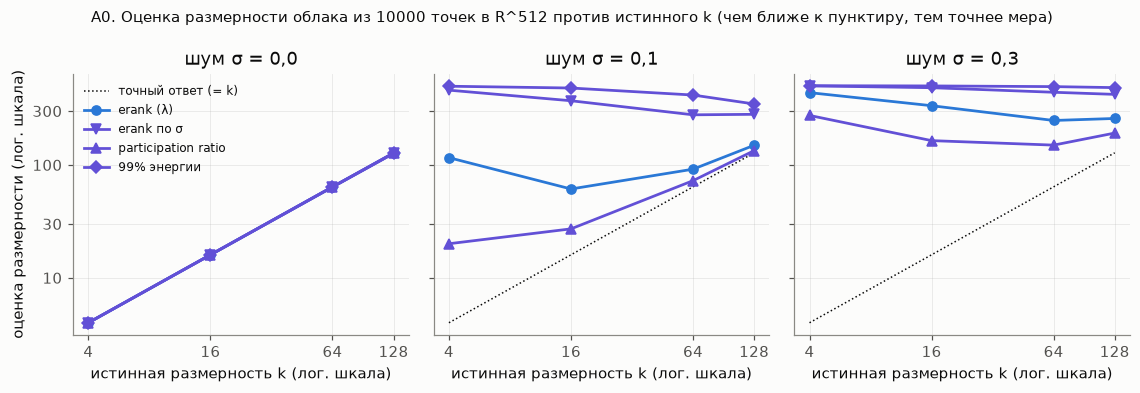

erank (λ) erank по σ participation ratio 99% энергии
шум σ k                                                       
0,0   4         4,0        4,0                 4,0         4,0
      16       16,0       16,0                16,0        16,0
      64       63,8       63,9                63,6        64,0
      128     127,2      127,8               126,4       127,0
0,1   4       116,0      459,5                20,0       498,0
      16       61,2      370,3                27,1       480,0
      64       91,7      277,9                72,6       416,0
      128     149,3      280,7               133,8       346,7
0,3   4       436,9      501,5               274,5       503,0
      16      334,7      483,1               164,2       501,0
      64      247,6      440,2               149,8       494,0
      128     258,0      421,7               191,6       484,0

**Вывод A0.** Без шума наибольшая относительная ошибка мер: erank (λ) 0,6%, erank по σ 0,2%, participation ratio 1,3%, 99% энергии 0,8%. С шумом ближе всего к k (среднее |ln(оценка/k)| по σ > 0) — **participation ratio**; при σ = 0,1 и k = 4 оценки: erank (λ) 116,0, erank по σ 459,5, participation ratio 20,0, 99% энергии 498,0.

In [9]:
E0_MEASURES = ["erank_energy", "erank_sv", "participation_ratio", "energy99"]
e0_mean = {(m, noise, k): float(np.mean([r["metrics"][m] for r in e0 if r["noise"] == noise and r["k"] == k]))
           for m in E0_MEASURES for noise in E0_NOISE for k in E0_K}
fig, axes = plt.subplots(1, len(E0_NOISE), figsize=(10.5, 3.6), sharey=True)
for ax, noise in zip(axes, E0_NOISE):
    ax.plot(E0_K, E0_K, color=PALETTE["teacher"], lw=1, ls=":", label="точный ответ (= k)")
    for m in E0_MEASURES:
        ax.plot(E0_K, [e0_mean[(m, noise, k)] for k in E0_K], **sty(m))
    ax.set(xscale="log", yscale="log", xlabel="истинная размерность k (лог. шкала)", title=f"шум σ = {num(noise, 1)}")
    ax.set_xticks(E0_K, [str(k) for k in E0_K])
    ax.xaxis.set_minor_locator(NullLocator())
log_ticks(axes[0].yaxis)
axes[0].set_ylabel("оценка размерности (лог. шкала)")
axes[0].legend(fontsize=8)
fig.suptitle(f"A0. Оценка размерности облака из {E0_N} точек в R^{E0_DIM} против истинного k "
             "(чем ближе к пунктиру, тем точнее мера)", fontsize=10)
plt.tight_layout()
plt.show()

display(pd.DataFrame({LABELS[m]: [num(e0_mean[(m, noise, k)], 1) for noise in E0_NOISE for k in E0_K]
                      for m in E0_MEASURES},
                     index=pd.MultiIndex.from_tuples([(num(noise, 1), k) for noise in E0_NOISE for k in E0_K],
                                                     names=["шум σ", "k"])))
clean_err = {m: max(abs(e0_mean[(m, 0.0, k)] - k) / k for k in E0_K) for m in E0_MEASURES}
noisy_err = {m: float(np.mean([abs(math.log(e0_mean[(m, nz, k)] / k)) for nz in E0_NOISE if nz > 0 for k in E0_K]))
             for m in E0_MEASURES}
best = min(noisy_err, key=noisy_err.get)
nz = E0_NOISE[1]
display(Markdown(
    "**Вывод A0.** Без шума наибольшая относительная ошибка мер: "
    + ", ".join(f"{LABELS[m]} {num(100 * clean_err[m], 1)}%" for m in E0_MEASURES)
    + f". С шумом ближе всего к k (среднее |ln(оценка/k)| по σ > 0) — **{LABELS[best]}**; "
    + f"при σ = {num(nz, 1)} и k = {E0_K[0]} оценки: "
    + ", ".join(f"{LABELS[m]} {num(e0_mean[(m, nz, E0_K[0])], 1)}" for m in E0_MEASURES) + "."))

### A1. Шаги 1–2 на синтетике: ученик и его erank против ширин учителя

Для каждого сида обучаются база ученика и slim-база (штраф L1 на γ BatchNorm, нужна правилу Slimming); меры
считаются на выходе ReLU каждого слоя (и до BN/ReLU) на 10 000 примеров валидации.

In [10]:
STUDENT_PARAMS = count_params(64, E3_STUDENT, 10, bn=True)
syn_datasets, syn_bases, syn_slims, syn_base_rows, syn_slim_rows = {}, {}, {}, {}, {}
for seed in SEEDS:
    sdata = syn_datasets[seed] = syn_data(seed)
    make = lambda: MLP(64, E3_STUDENT, 10, bn=True).to(DEVICE)
    syn_bases[seed], syn_base_rows[seed] = trained(
        f"syn_base|s{seed}|e{E1_EPOCHS}", make, lambda: fit_syn_base(sdata, seed, 0.0))
    syn_slims[seed], syn_slim_rows[seed] = trained(
        f"syn_slim|l1={E3_SLIM_L1}|s{seed}|e{E1_EPOCHS}", make, lambda: fit_syn_base(sdata, seed, E3_SLIM_L1))
    log(f"A1: сид {seed}: ученик val MSE {syn_base_rows[seed]['val_mse']:.4f}, "
        f"slim {syn_slim_rows[seed]['val_mse']:.4f}, {syn_base_rows[seed]['train_seconds']} с на обучение")
print(f"ученик {E3_STUDENT}: {STUDENT_PARAMS} параметров; учитель {E1B_TEACHER}: "
      f"{count_params(64, E1B_TEACHER, 10, bn=False)} параметров")

2026-11-08 09:34:20  A1: сид 0: ученик val MSE 0.0361, slim 0.0144, 6.99 с на обучение


2026-11-08 09:34:20  A1: сид 1: ученик val MSE 0.0374, slim 0.0200, 6.66 с на обучение


2026-11-08 09:34:21  A1: сид 2: ученик val MSE 0.0448, slim 0.0210, 6.72 с на обучение


2026-11-08 09:34:21  A1: сид 3: ученик val MSE 0.0342, slim 0.0165, 6.83 с на обучение


2026-11-08 09:34:21  A1: сид 4: ученик val MSE 0.0508, slim 0.0300, 7.72 с на обучение


ученик [256, 256, 256]: 152330 параметров; учитель [64, 8, 32]: 5298 параметров


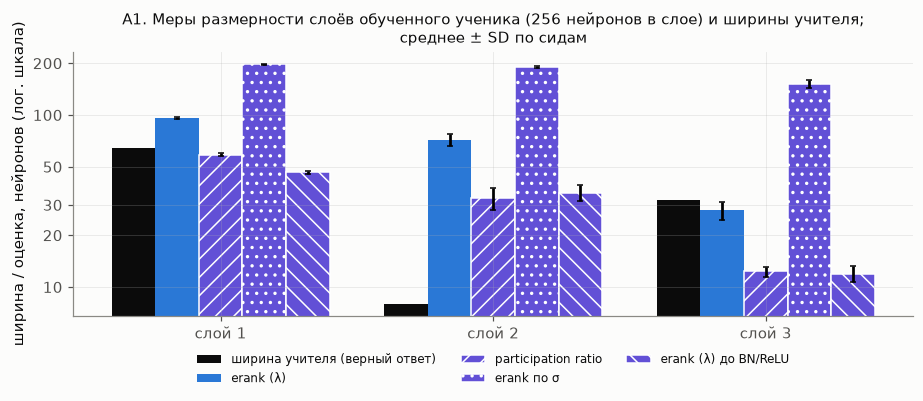

,слой 1,слой 2,слой 3
erank (λ),"95,8","71,7","27,9"
participation ratio,"58,9","32,7","12,3"
erank по σ,"197,3","191,2","152,1"
erank (λ) до BN/ReLU,"46,3","35,4","12,0"
живые нейроны,256,256,256
"доля |γ| < 0,01 у slim-базы","0,40","0,64","0,48"


**Вывод A1.** Учитель [64, 8, 32]; erank (λ) ученика по слоям: 95,8 / 71,7 / 27,9, participation ratio: 58,9 / 32,7 / 12,3. Spearman мер с шириной учителя по 3 слоям (среднее по сидам): erank (λ) 0,50, participation ratio 0,50, erank по σ 0,50, erank (λ) до BN/ReLU 0,50. Самый «узкий» слой по erank (λ) — слой 3 (у учителя — слой 2). val MSE базы 0,0407, slim-базы 0,0204.

In [11]:
A1_MEASURES = ["erank_energy", "participation_ratio", "erank_sv", "erank_energy_pre"]
syn_vals = {m: np.array([[r["layers"][l][m] for l in range(3)] for r in syn_base_rows.values()]) for m in A1_MEASURES}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x, w = np.arange(3), 0.8 / (len(A1_MEASURES) + 1)
ax.bar(x - 0.4 + w / 2, E1B_TEACHER, w, color=PALETTE["teacher"], label="ширина учителя (верный ответ)")
for i, m in enumerate(A1_MEASURES, 1):
    mu = syn_vals[m].mean(0)
    sd = syn_vals[m].std(0, ddof=1) if len(SEEDS) > 1 else None
    ax.bar(x - 0.4 + w * (i + 0.5), mu, w, yerr=sd, capsize=2, **bar_sty(m))
ax.set_yscale("log")
log_ticks(ax.yaxis)
ax.set_xticks(x, ["слой 1", "слой 2", "слой 3"])
ax.set_ylabel("ширина / оценка, нейронов (лог. шкала)")
ax.set_title("A1. Меры размерности слоёв обученного ученика (256 нейронов в слое) и ширины учителя;\n"
             "среднее ± SD по сидам", fontsize=10)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

rows_tab = {LABELS[m]: [num(v, 1) for v in syn_vals[m].mean(0)] for m in A1_MEASURES}
rows_tab["живые нейроны"] = [num(np.mean([r["layers"][l]["alive"] for r in syn_base_rows.values()]), 0) for l in range(3)]
rows_tab["доля |γ| < 0,01 у slim-базы"] = [num(np.mean([r["gamma_small_fraction"][l] for r in syn_slim_rows.values()]), 2)
                                          for l in range(3)]
display(pd.DataFrame(rows_tab, index=["слой 1", "слой 2", "слой 3"]).T)
rho_teacher = {m: float(np.mean([spearman([row["layers"][l][m] for l in range(3)], E1B_TEACHER)
                                 for row in syn_base_rows.values()])) for m in A1_MEASURES}
mins = {m: int(np.argmin(syn_vals[m].mean(0))) + 1 for m in A1_MEASURES}
display(Markdown(
    f"**Вывод A1.** Учитель {E1B_TEACHER}; erank (λ) ученика по слоям: "
    f"{' / '.join(num(v, 1) for v in syn_vals['erank_energy'].mean(0))}, participation ratio: "
    f"{' / '.join(num(v, 1) for v in syn_vals['participation_ratio'].mean(0))}. Spearman мер с шириной учителя "
    f"по 3 слоям (среднее по сидам): " + ", ".join(f"{LABELS[m]} {num(rho_teacher[m], 2)}" for m in A1_MEASURES)
    + f". Самый «узкий» слой по erank (λ) — слой {mins['erank_energy']} (у учителя — слой 2). "
    f"val MSE базы {num(np.mean([r['val_mse'] for r in syn_base_rows.values()]), 4)}, "
    f"slim-базы {num(np.mean([r['val_mse'] for r in syn_slim_rows.values()]), 4)}."))

### A2. Шаг 3 на синтетике: правила выбора ширин, обучение с нуля

Каждое правило предлагает ширины под потолок 10 / 5 / 3% параметров ученика (минимум 4 нейрона в слое); сеть этой
архитектуры обучается с нуля тем же рецептом, сравнивается MSE на тесте. `teacher` — ориентир-оракул (ширины ∝
ширинам учителя), Taylor и Slimming — глобальное ранжирование нейронов.

In [12]:
syn_rows = []
for seed in SEEDS:
    sdata, base, slim, metrics = syn_datasets[seed], syn_bases[seed], syn_slims[seed], syn_base_rows[seed]["layers"]
    for budget in E3_BUDGETS:
        target = int(budget * STUDENT_PARAMS)
        for method in E3_METHODS:
            widths = cached(f"syn_widths|{method}|{budget}|s{seed}|e{E1_EPOCHS}", lambda: {"widths": choose_widths(
                method, base, metrics, sdata, target, seed, task="regress", floor=E3_FLOOR, slim=slim,
                teacher_widths=E1B_TEACHER)[0]})["widths"]
            syn_rows.append({**scratch_syn(sdata, widths, seed), "method": method, "budget": budget})
    log(f"A2: сид {seed} готов")

2026-11-08 09:34:21  A2: сид 0 готов


2026-11-08 09:34:21  A2: сид 1 готов


2026-11-08 09:34:21  A2: сид 2 готов


2026-11-08 09:34:21  A2: сид 3 готов


2026-11-08 09:34:21  A2: сид 4 готов

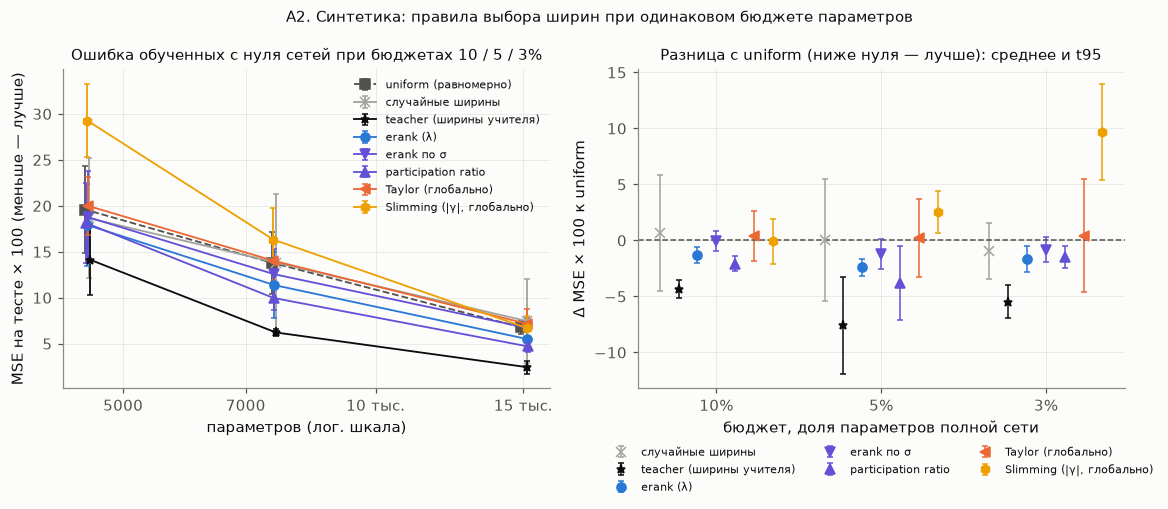

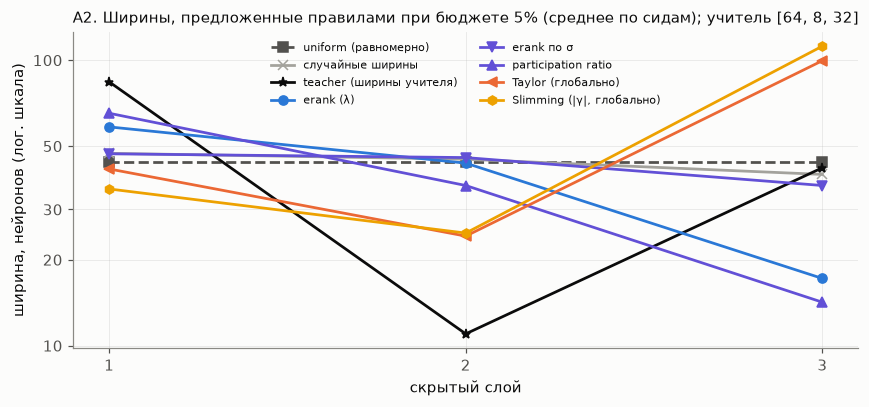

,10%,5%,3%
"uniform (равномерно), абсолютная","6,79","13,79","19,59"
случайные ширины,"+0,67 [−4,51; +5,84]","+0,04 [−5,37; +5,45]","−0,93 [−3,41; +1,54]"
teacher (ширины учителя),"−4,34 [−5,15; −3,53]","−7,57 [−11,91; −3,22]","−5,46 [−6,94; −3,98]"
erank (λ),"−1,28 [−1,99; −0,58]","−2,42 [−3,19; −1,64]","−1,66 [−2,80; −0,52]"
erank по σ,"−0,06 [−0,94; +0,83]","−1,23 [−2,58; +0,11]","−0,81 [−1,97; +0,35]"
participation ratio,"−2,08 [−2,75; −1,41]","−3,81 [−7,14; −0,49]","−1,48 [−2,42; −0,54]"
Taylor (глобально),"+0,39 [−1,84; +2,62]","+0,24 [−3,25; +3,73]","+0,42 [−4,61; +5,44]"
"Slimming (|γ|, глобально)","−0,09 [−2,14; +1,95]","+2,53 [+0,69; +4,38]","+9,69 [+5,37; +14,01]"


**Вывод A2** (MSE × 100, парная разница с uniform по бюджетам 10% / 5% / 3%, n = 5; ниже нуля — лучше uniform; t95 без поправки на множественные сравнения). Teacher (ширины учителя): −4,34 / −7,57 / −5,46 (интервал t95 ниже нуля в 3, выше нуля в 0 из 3); erank (λ): −1,28 / −2,42 / −1,66 (интервал t95 ниже нуля в 3, выше нуля в 0 из 3); participation ratio: −2,08 / −3,81 / −1,48 (интервал t95 ниже нуля в 3, выше нуля в 0 из 3); erank по σ: −0,06 / −1,23 / −0,81 (интервал t95 ниже нуля в 0, выше нуля в 0 из 3); Taylor (глобально): +0,39 / +0,24 / +0,42 (интервал t95 ниже нуля в 0, выше нуля в 0 из 3); Slimming (|γ|, глобально): −0,09 / +2,53 / +9,69 (интервал t95 ниже нуля в 0, выше нуля в 2 из 3). Доля выигрыша teacher, которую забирает erank (λ): 31%, participation ratio: 42%.

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ax = axes[0]
for m in E3_METHODS:
    pts = [(np.mean([r["params"] for r in syn_rows if r["method"] == m and r["budget"] == b]),
            *mean_sd([100 * r["test_mse"] for r in syn_rows if r["method"] == m and r["budget"] == b]))
           for b in E3_BUDGETS]
    px, py, pe = zip(*pts)
    ax.errorbar(px, py, yerr=pe, capsize=2, lw=1.2, **sty(m))
ax.set(xscale="log", xlabel="параметров (лог. шкала)", ylabel="MSE на тесте × 100 (меньше — лучше)")
log_ticks(ax.xaxis)
ax.set_title(f"Ошибка обученных с нуля сетей при бюджетах {' / '.join(f'{100 * b:g}' for b in E3_BUDGETS)}%",
             fontsize=10)
ax.legend(fontsize=7.5)
delta_panel(axes[1], syn_rows, [m for m in E3_METHODS if m != "uniform"], E3_BUDGETS, "test_mse", 100,
            "Δ MSE × 100 к uniform", "Разница с uniform (ниже нуля — лучше): среднее и t95")
fig.suptitle("A2. Синтетика: правила выбора ширин при одинаковом бюджете параметров", fontsize=10)
plt.tight_layout()
plt.show()

b_show = E3_BUDGETS[1]
fig, ax = plt.subplots(figsize=(8, 3.8))
for m in E3_METHODS:
    ws = np.array([r["widths"] for r in syn_rows if r["method"] == m and r["budget"] == b_show])
    ax.plot([1, 2, 3], ws.mean(0), **sty(m))
ax.set(yscale="log", xticks=[1, 2, 3], xlabel="скрытый слой", ylabel="ширина, нейронов (лог. шкала)")
log_ticks(ax.yaxis)
ax.set_title(f"A2. Ширины, предложенные правилами при бюджете {100 * b_show:g}% (среднее по сидам); "
             f"учитель {E1B_TEACHER}", fontsize=10)
ax.legend(fontsize=7.5, ncol=2)
plt.tight_layout()
plt.show()

syn_summ = {(m, b): paired_summary(paired(syn_rows, m, b, "test_mse")) for m in E3_METHODS[1:] for b in E3_BUDGETS}
tab = {LABELS[m]: [ci_text(syn_summ[(m, b)]) for b in E3_BUDGETS] for m in E3_METHODS[1:]}
tab = {LABELS["uniform"] + ", абсолютная": [num(np.mean([100 * r["test_mse"] for r in syn_rows if r["method"] == "uniform"
                                                         and r["budget"] == b]), 2) for b in E3_BUDGETS], **tab}
display(pd.DataFrame(tab, index=[f"{100 * b:g}%" for b in E3_BUDGETS]).T)


def share_of_teacher(m):
    vals = [syn_summ[(m, b)]["mean_pp"] / syn_summ[("teacher", b)]["mean_pp"] for b in E3_BUDGETS
            if syn_summ[("teacher", b)]["mean_pp"] and syn_summ[("teacher", b)]["mean_pp"] < 0]
    return float(np.mean(vals)) if vals else float("nan")


def better_count(m):
    if len(SEEDS) < 2:
        return "интервал при n = 1 не оценивается"
    signs = [ci_sign(syn_summ[(m, b)]) for b in E3_BUDGETS]
    return f"интервал t95 ниже нуля в {signs.count(-1)}, выше нуля в {signs.count(1)} из {len(E3_BUDGETS)}"


def share_text(m):
    s = share_of_teacher(m)
    return "не определена (teacher не лучше uniform)" if math.isnan(s) else f"{num(100 * s, 0)}%"


display(Markdown(
    f"**Вывод A2** (MSE × 100, парная разница с uniform по бюджетам {' / '.join(f'{100 * b:g}%' for b in E3_BUDGETS)}, "
    f"n = {len(SEEDS)}; ниже нуля — лучше uniform; t95 без поправки на множественные сравнения). "
    + cap("; ".join(f"{LABELS[m]}: {' / '.join(num(syn_summ[(m, b)]['mean_pp'], 2, True) for b in E3_BUDGETS)} "
                    f"({better_count(m)})"
                    for m in ["teacher", "erank_energy", "participation_ratio", "erank_sv", "taylor_global",
                              "slimming_global"]))
    + f". Доля выигрыша teacher, которую забирает erank (λ): {share_text('erank_energy')}, "
    f"participation ratio: {share_text('participation_ratio')}."))

## Часть B. MNIST, MLP 784 → 1024×3 → 10

Картинка — вектор из 784 чисел, нормированный одним средним и одним SD по официальному train; валидация — первые
10 000 примеров перестановки `Generator(0)` из train (обучение на остальных 50 000), test — официальные 10 000 и
используется только для итоговых чисел. Как в основной серии, статистики нормировки посчитаны по train вместе с
валидацией (test не участвует). Каждый скрытый блок: Linear → BatchNorm → ReLU.

In [14]:
DATA_ROOT = next((p for p in [Path("data"), Path("../data")] if (p / "MNIST/raw/train-images-idx3-ubyte").is_file()), None)
if DATA_ROOT is None and not DOWNLOAD:
    raise FileNotFoundError("нет MNIST/raw/train-images-idx3-ubyte в data/ или ../data/ (или поставьте DOWNLOAD = True)")
data = load_vision("mnist", root=str(DATA_ROOT or Path("data")), device=DEVICE, download=DOWNLOAD)
if N_TRAIN:
    data["x_train"], data["y_train"] = data["x_train"][:N_TRAIN], data["y_train"][:N_TRAIN]
    data["x_val"], data["y_val"] = data["x_val"][:N_VAL], data["y_val"][:N_VAL]
IN_DIM = data["x_train"].shape[1]
x_fit, y_fit = data["x_train"][:N_FIT], data["y_train"][:N_FIT]
BASE_PARAMS = count_params(IN_DIM, BASE_WIDTHS, 10)
print({k: tuple(v.shape) for k, v in data.items()}, "| параметров полной сети:", BASE_PARAMS)

{'x_train': (50000, 784), 'y_train': (50000,), 'x_val': (10000, 784), 'y_val': (10000,), 'x_test': (10000, 784), 'y_test': (10000,)} | параметров полной сети: 2919434


### Шаг 1. Базовая сеть; erank по слоям и по эпохам

По 5 сидов: база и slim-база (штраф L1 на γ, 1e-3), 20 эпох. После каждой эпохи erank всех слоёв считается на
валидации; контроль — та же инициализация до обучения с пересчитанными статистиками BatchNorm.

In [15]:
def fit_mnist_base(seed: int, l1_gamma: float):
    torch.manual_seed(seed)
    model = MLP(IN_DIM, BASE_WIDTHS, 10).to(DEVICE)
    untrained_raw = layer_metrics(model, data["x_val"])   # as in the main series: BN running statistics not set
    control = copy.deepcopy(model)
    recalibrate_bn(control, x_fit)                         # control: the same init with BN statistics recomputed
    untrained = layer_metrics(control, data["x_val"])
    history = train(model, data, EPOCHS, LR, WD, BATCH, seed, l1_gamma=l1_gamma, probe_x=data["x_val"], verbose=False)
    return model, {"seed": seed, "l1_gamma": l1_gamma, "history": history, "val_acc": history[-1]["val_acc"],
                   "test_acc": evaluate(model, data["x_test"], data["y_test"], "classify")["acc"],
                   "train_acc": evaluate(model, x_fit, y_fit, "classify")["acc"],
                   "layers": layer_metrics(model, data["x_val"]), "untrained": untrained,
                   "untrained_raw": untrained_raw, "gamma_small_fraction": gamma_small_fraction(model),
                   "train_seconds": round(sum(h["seconds"] for h in history), 2)}


base_nets, slim_nets, base_rows, slim_rows = {}, {}, {}, {}
for seed in SEEDS:
    make = lambda: MLP(IN_DIM, BASE_WIDTHS, 10).to(DEVICE)
    base_nets[seed], base_rows[seed] = trained(f"base|mnist|s{seed}|e{EPOCHS}", make,
                                               lambda: fit_mnist_base(seed, 0.0))
    slim_nets[seed], slim_rows[seed] = trained(f"slim|mnist|l1={SLIM_L1['mnist']}|s{seed}|e{EPOCHS}", make,
                                               lambda: fit_mnist_base(seed, SLIM_L1["mnist"]))
    log(f"Шаг 1: сид {seed}: база test {100 * base_rows[seed]['test_acc']:.2f}%, "
        f"slim {100 * slim_rows[seed]['test_acc']:.2f}%, {base_rows[seed]['train_seconds']} с на обучение")

2026-11-08 09:34:21  Шаг 1: сид 0: база test 98.55%, slim 98.56%, 4.55 с на обучение


2026-11-08 09:34:21  Шаг 1: сид 1: база test 98.53%, slim 98.57%, 4.53 с на обучение


2026-11-08 09:34:21  Шаг 1: сид 2: база test 98.66%, slim 98.59%, 4.83 с на обучение


2026-11-08 09:34:21  Шаг 1: сид 3: база test 98.44%, slim 98.59%, 4.71 с на обучение


2026-11-08 09:34:21  Шаг 1: сид 4: база test 98.59%, slim 98.45%, 5.56 с на обучение


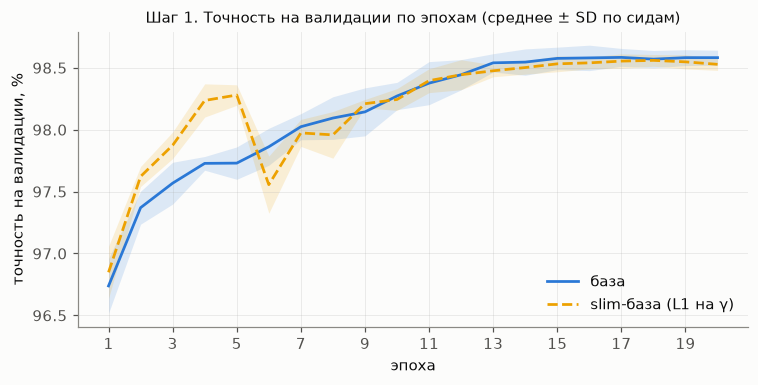

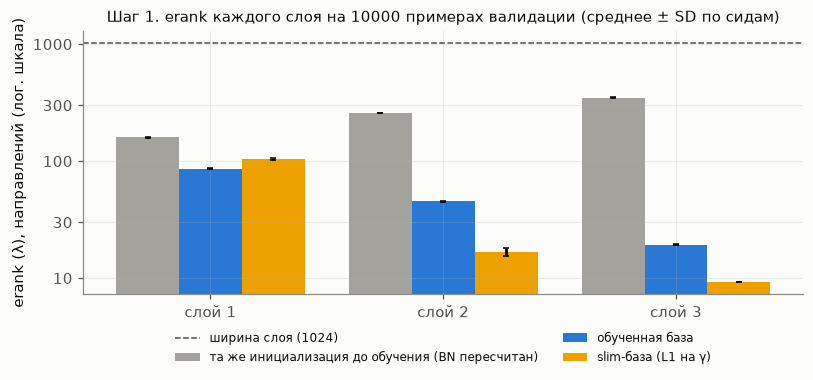

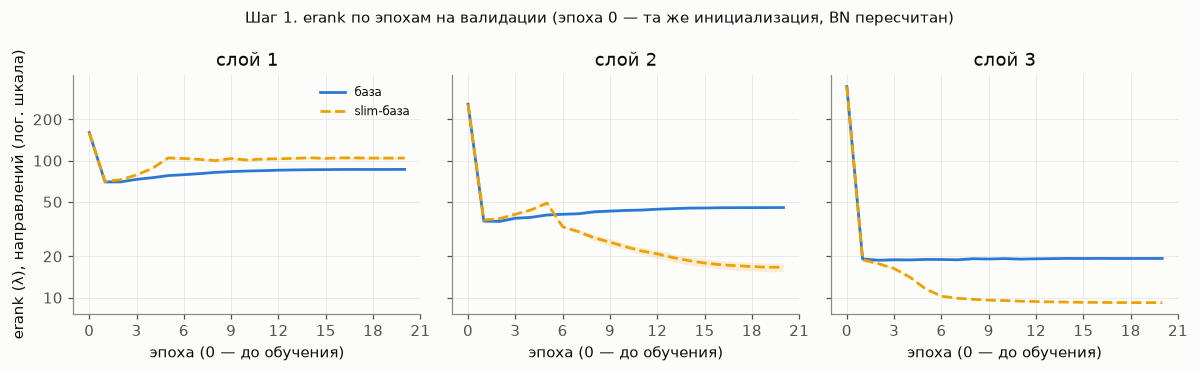

,слой 1,слой 2,слой 3
"erank: до обучения, BN пересчитан","160,2","258,0","347,5"
"erank: до обучения, BN не пересчитан","119,1","141,3","148,5"
erank: после 1-й эпохи,"69,9","36,2","19,2"
erank: обученная база,"86,3","45,4","19,3"
erank: slim-база,"104,5","16,7","9,2"
живые нейроны базы,"1024,0","1024,0","1024,0"
"доля |γ| < 0,01 у slim-базы","0,78","0,89","0,79"


**Вывод шага 1.** Точность на тесте: база 98,55 ± 0,08%, slim-база 98,55 ± 0,06% (n = 5), 4,8 с на обучение. erank (λ) обученной базы по слоям: 86,3 / 45,4 / 19,3 из 1024; до обучения (BN пересчитан): 160,2 / 258,0 / 347,5; отношение «до / после обучения»: 1,9 / 5,7 / 18,0. У slim-базы: 104,5 / 16,7 / 9,2. Живых нейронов в базе: 1024 / 1024 / 1024.

In [16]:
ep = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(7, 3.6))
for rows, key, ls, name in [(base_rows, "erank", "-", "база"), (slim_rows, "slimming", "--", "slim-база (L1 на γ)")]:
    acc = np.array([[100 * h["val_acc"] for h in r["history"]] for r in rows.values()])
    mu, sd = acc.mean(0), acc.std(0, ddof=1) if len(SEEDS) > 1 else np.zeros(len(ep))
    ax.plot(ep, mu, color=PALETTE[key], ls=ls, label=name)
    ax.fill_between(ep, mu - sd, mu + sd, color=PALETTE[key], alpha=0.15, lw=0)
ax.set(xlabel="эпоха", ylabel="точность на валидации, %", xticks=ep[::max(1, len(ep) // 10)])
ax.set_title("Шаг 1. Точность на валидации по эпохам (среднее ± SD по сидам)", fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()

def layer_values(rows, key="layers", m="erank_energy"):
    return np.array([[r[key][l][m] for l in range(3)] for r in rows.values()])

er = {"untrained": layer_values(base_rows, "untrained"), "base": layer_values(base_rows),
      "slim": layer_values(slim_rows), "raw": layer_values(base_rows, "untrained_raw")}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x, w = np.arange(3), 0.27
for i, (k, color, name) in enumerate([("untrained", PALETTE["random"], "та же инициализация до обучения (BN пересчитан)"),
                                      ("base", PALETTE["erank"], "обученная база"),
                                      ("slim", PALETTE["slimming"], "slim-база (L1 на γ)")]):
    sd = er[k].std(0, ddof=1) if len(SEEDS) > 1 else None
    ax.bar(x - w + i * w, er[k].mean(0), w, yerr=sd, capsize=2, color=color, label=name)
ax.axhline(BASE_WIDTHS[0], color=PALETTE["uniform"], ls="--", lw=1, label="ширина слоя (1024)")
ax.set(yscale="log", ylabel="erank (λ), направлений (лог. шкала)")
log_ticks(ax.yaxis)
ax.set_xticks(x, ["слой 1", "слой 2", "слой 3"])
ax.set_title(f"Шаг 1. erank каждого слоя на {len(data['x_val'])} примерах валидации (среднее ± SD по сидам)",
             fontsize=10)
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for l, ax in enumerate(axes):
    for rows, key, ls, name in [(base_rows, "erank", "-", "база"), (slim_rows, "slimming", "--", "slim-база")]:
        traj = np.array([[r["untrained"][l]["erank_energy"]] + [h["layers"][l]["erank_energy"] for h in r["history"]]
                         for r in rows.values()])
        mu, sd = traj.mean(0), traj.std(0, ddof=1) if len(SEEDS) > 1 else np.zeros(traj.shape[1])
        ax.plot(np.arange(EPOCHS + 1), mu, color=PALETTE[key], ls=ls, label=name)
        ax.fill_between(np.arange(EPOCHS + 1), mu - sd, mu + sd, color=PALETTE[key], alpha=0.15, lw=0)
    ax.set(yscale="log", xlabel="эпоха (0 — до обучения)", title=f"слой {l + 1}")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
log_ticks(axes[0].yaxis)
axes[0].set_ylabel("erank (λ), направлений (лог. шкала)")
axes[0].legend(fontsize=8)
fig.suptitle("Шаг 1. erank по эпохам на валидации (эпоха 0 — та же инициализация, BN пересчитан)", fontsize=10)
plt.tight_layout()
plt.show()

acc_b, acc_s = mean_sd([100 * r["test_acc"] for r in base_rows.values()]), mean_sd([100 * r["test_acc"] for r in slim_rows.values()])
first = np.array([[r["history"][0]["layers"][l]["erank_energy"] for l in range(3)] for r in base_rows.values()]).mean(0)
s1_tab = {"erank: до обучения, BN пересчитан": er["untrained"].mean(0),
          "erank: до обучения, BN не пересчитан": er["raw"].mean(0), "erank: после 1-й эпохи": first,
          "erank: обученная база": er["base"].mean(0), "erank: slim-база": er["slim"].mean(0),
          "живые нейроны базы": layer_values(base_rows, m="alive").mean(0),
          "доля |γ| < 0,01 у slim-базы": np.array([r["gamma_small_fraction"] for r in slim_rows.values()]).mean(0)}
display(pd.DataFrame({k: [num(v, 2 if "доля" in k else 1) for v in vals] for k, vals in s1_tab.items()},
                     index=["слой 1", "слой 2", "слой 3"]).T)
display(Markdown(
    f"**Вывод шага 1.** Точность на тесте: база {num(acc_b[0])} ± {num(acc_b[1])}%, slim-база {num(acc_s[0])} ± "
    f"{num(acc_s[1])}% (n = {len(SEEDS)}), {num(np.mean([r['train_seconds'] for r in base_rows.values()]), 1)} с "
    f"на обучение. erank (λ) обученной базы по слоям: {' / '.join(num(v, 1) for v in er['base'].mean(0))} из 1024; "
    f"до обучения (BN пересчитан): {' / '.join(num(v, 1) for v in er['untrained'].mean(0))}; отношение «до / после "
    f"обучения»: {' / '.join(num(a / b, 1) for a, b in zip(er['untrained'].mean(0), er['base'].mean(0)))}. "
    f"У slim-базы: {' / '.join(num(v, 1) for v in er['slim'].mean(0))}. Живых нейронов в базе: "
    f"{' / '.join(num(v, 0) for v in layer_values(base_rows, m='alive').mean(0))}."))

### Шаг 2. Какая мера лучше предсказывает, насколько можно сжать слой

Сжимаемость измеряется напрямую: один слой сужается, остальные полные, статистики BN пересчитываются, без дообучения.
Срез L1 оставляет k нейронов с наибольшей L1-нормой входящих весов (среднее выброшенных уходит в bias); PCA
оставляет все нейроны, но следующий слой видит только k главных направлений (для PCA сетка k дополнена 2, 4, 8:
последнему слою нужно мало направлений). need — наименьшее k с потерей точности на валидации ≤ 1 п.п.; если это
наименьшее проверенное k, need — лишь верхняя граница («≤»). Меры: после ReLU, до BN/ReLU (выход Linear) и контроль
«только дисперсии нейронов».
Вариант статьи arXiv 2607.19315 (erank одной картинки по её позициям/токенам) к MLP не применим: у картинки здесь
один вектор, а не набор позиций.

In [17]:
diag_rows, sens = {}, {}
for seed in SEEDS:
    base = base_nets[seed]
    diag_rows[seed] = cached(f"diag|s{seed}|e{EPOCHS}", lambda: {
        "layers": [diag_metrics(h) for h in hidden_activations(base, data["x_val"])]})
    ref = cached(f"sens|full|s{seed}|e{EPOCHS}", lambda: {"val_acc": val_after_recal(copy.deepcopy(base))})["val_acc"]
    l1 = unit_scores(base, "l1")
    basis, rows = [], []  # the PCA basis is computed only when a PCA row is missing

    def pca_row():
        if not basis:
            basis.extend(pca_basis(base, x_fit))
        return {"val_acc": val_after_recal(pca_cut(base, l, k, basis))}

    for l, width in enumerate(base.widths):
        ks = sorted({max(1, round(f * width)) for f in SENS_FRACTIONS})
        for k in ks:
            keep = [torch.arange(w) for w in base.widths]
            keep[l] = top_k(l1[l], k)
            prune = cached(f"sens|prune|l{l + 1}|{k}|s{seed}|e{EPOCHS}",
                           lambda: {"val_acc": val_after_recal(keep_units(base, keep, x_fit))})
            rows.append({"kind": "prune", "layer": l, "k": k, "val_acc": prune["val_acc"]})
        for k in sorted(set(ks) | {k for k in PCA_SMALL_K if k < width}):
            pca = cached(f"sens|pca|l{l + 1}|{k}|s{seed}|e{EPOCHS}", pca_row)
            rows.append({"kind": "pca", "layer": l, "k": k, "val_acc": pca["val_acc"]})
    sens[seed] = {"ref": ref, "rows": rows}
    log(f"Шаг 2: сид {seed}: {len(rows)} срезов одного слоя")


def sens_rows(seed, kind, layer):
    return sorted((r for r in sens[seed]["rows"] if r["kind"] == kind and r["layer"] == layer), key=lambda r: r["k"])


need = {kind: {s: [need_from_rows(sens[s]["ref"], sens_rows(s, kind, l), w) for l, w in enumerate(BASE_WIDTHS)]
               for s in SEEDS} for kind in ("prune", "pca")}
# need equal to the smallest k tried is an upper bound (the layer might do with even fewer), not a measurement
need_floor = {kind: {s: [need[kind][s][l] == sens_rows(s, kind, l)[0]["k"] for l in range(len(BASE_WIDTHS))]
                     for s in SEEDS} for kind in need}
print("need, срез L1:", need["prune"], "\nneed, PCA:", need["pca"])

2026-11-08 09:34:22  Шаг 2: сид 0: 99 срезов одного слоя


2026-11-08 09:34:22  Шаг 2: сид 1: 99 срезов одного слоя


2026-11-08 09:34:22  Шаг 2: сид 2: 99 срезов одного слоя


2026-11-08 09:34:22  Шаг 2: сид 3: 99 срезов одного слоя


2026-11-08 09:34:22  Шаг 2: сид 4: 99 срезов одного слоя


need, срез L1: {0: [384, 320, 256], 1: [512, 320, 256], 2: [512, 256, 320], 3: [384, 320, 256], 4: [512, 256, 256]} 
need, PCA: {0: [32, 16, 8], 1: [64, 16, 8], 2: [32, 16, 8], 3: [32, 16, 8], 4: [32, 16, 8]}


,слой 1,слой 2,слой 3,ρ с need (срез L1),ρ с need (PCA)
erank (λ),"86,3","45,4","19,3","0,87 (n=5)","1,00 (n=5)"
erank по σ,"587,0","453,9","282,5","0,87 (n=5)","1,00 (n=5)"
participation ratio,"33,0","20,5","11,4","0,87 (n=5)","1,00 (n=5)"
stable rank,"12,3","9,5","6,8","0,87 (n=5)","1,00 (n=5)"
90% энергии,"148,2","57,4","17,2","0,87 (n=5)","1,00 (n=5)"
99% энергии,"706,4","497,0","173,2","0,87 (n=5)","1,00 (n=5)"
erank (λ) до BN/ReLU,"29,4","20,5","12,2","0,87 (n=5)","1,00 (n=5)"
participation ratio до BN/ReLU,"17,0","12,8","8,9","0,87 (n=5)","1,00 (n=5)"
erank по дисперсиям (контроль),"1007,8","1012,1","1016,2","−0,87 (n=5)","−1,00 (n=5)"
живые нейроны (контроль),"1024,0","1024,0","1024,0",н/д (n=0),н/д (n=0)


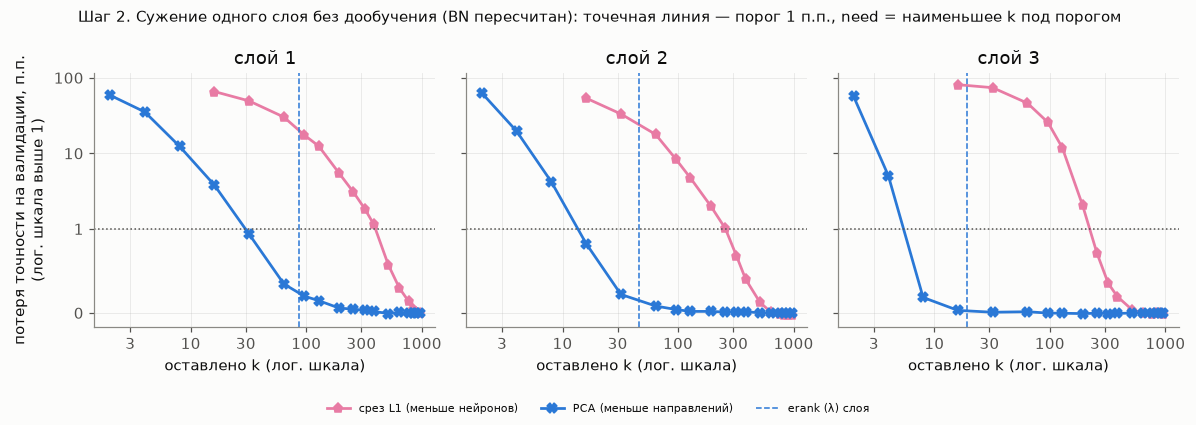

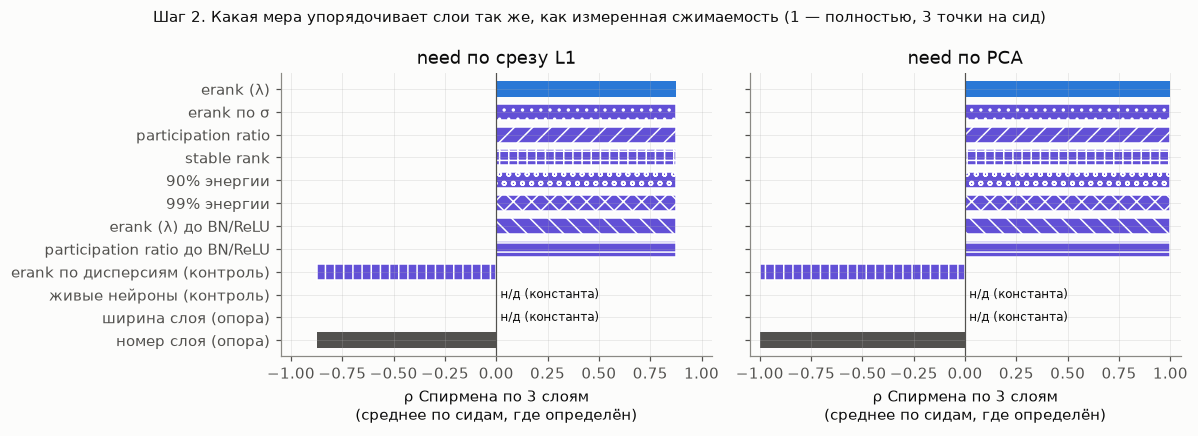

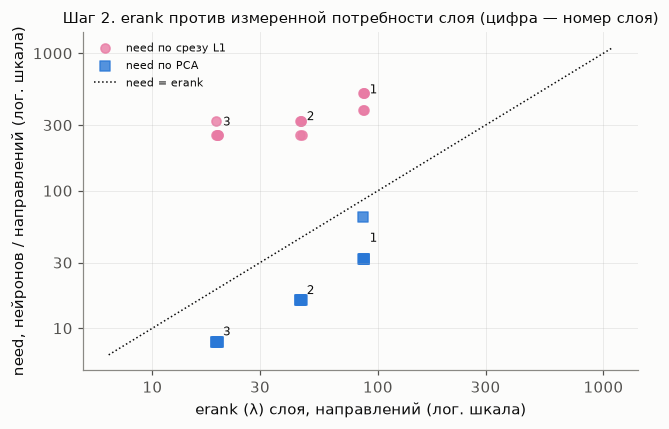

**Вывод шага 2.** Сколько нейронов нужно слою (потеря ≤ 1 п.п. без дообучения, среднее по 5 сидам): по срезу L1 461 / 294 / 269, по PCA 38 / 16 / 8; erank (λ): 86,3 / 45,4 / 19,3. Spearman erank (λ) с need: 0,87 (срез L1), 1,00 (PCA); наибольший ρ со срезом L1 — erank (λ), erank по σ, participation ratio, stable rank, 90% энергии, 99% энергии, erank (λ) до BN/ReLU, participation ratio до BN/ReLU (0,87), с PCA — erank (λ), erank по σ, participation ratio, stable rank, 90% энергии, 99% энергии, erank (λ) до BN/ReLU, participation ratio до BN/ReLU (1,00). Ориентир «номер слоя»: −0,87 (срез L1), −1,00 (PCA) — тот же |ρ|, что у лучших мер (срез L1 и PCA): need убывает с глубиной, и по 3 слоям спектральные меры не отличаются от простого правила «глубже — уже». По 3 слоям на одном сиде ρ принимает лишь несколько значений (±1 и ±0,5, при совпадающих значениях ещё ±0,87 и 0; при равных во всех слоях не определён), среднее берётся по сидам, где ρ определён (n в таблице), поэтому сравнение мер описательное.

In [18]:
S2_MEASURES = ["erank_energy", "erank_sv", "participation_ratio", "stable_rank", "energy90", "energy99",
               "erank_energy_pre", "participation_ratio_pre", "erank_energy_diag", "alive", "width", "depth"]


def measure_values(seed, m):
    layers = base_rows[seed]["layers"]
    if m == "width":
        return [l["dim"] for l in layers]
    if m == "depth":
        return [1, 2, 3]
    if m.endswith("_diag"):
        return [d[m[:-5]] for d in diag_rows[seed]["layers"]]
    return [l[m] for l in layers]


def rho(m, kind):
    """Spearman of the 3 layers' measure with their need: (mean over the seeds where it is defined, number of
    such seeds). It is undefined when the measure or the need is equal in all 3 layers."""
    vals = [spearman(measure_values(s, m), need[kind][s]) for s in SEEDS]
    vals = [v for v in vals if not math.isnan(v)]
    return (float(np.mean(vals)) if vals else float("nan")), len(vals)


rho_n = {kind: {m: rho(m, kind) for m in S2_MEASURES} for kind in ("prune", "pca")}
rhos = {kind: {m: v[0] for m, v in d.items()} for kind, d in rho_n.items()}
tab = pd.DataFrame({LABELS[m]: [num(np.mean([measure_values(s, m)[l] for s in SEEDS]), 1) for l in range(3)]
                    + [f"{num(rho_n[kind][m][0])} (n={rho_n[kind][m][1]})" for kind in ("prune", "pca")]
                    for m in S2_MEASURES},
                   index=["слой 1", "слой 2", "слой 3", "ρ с need (срез L1)", "ρ с need (PCA)"]).T
need_mean = {kind: np.array([need[kind][s] for s in SEEDS]).mean(0) for kind in need}


def need_text(kind, l, digits=1):
    """Mean need of a layer over the seeds; '≤' when on some seed it sits at the smallest k tried (upper bound)."""
    return ("≤ " if any(need_floor[kind][s][l] for s in SEEDS) else "") + num(need_mean[kind][l], digits)


tab.loc["need: срез L1, ≤ 1 п.п."] = [need_text("prune", l) for l in range(3)] + ["", ""]
tab.loc["need: PCA, ≤ 1 п.п."] = [need_text("pca", l) for l in range(3)] + ["", ""]
display(tab)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for l, ax in enumerate(axes):
    for kind, key, name in [("prune", "l1", "срез L1 (меньше нейронов)"), ("pca", "pca", "PCA (меньше направлений)")]:
        ks = [r["k"] for r in sens_rows(SEEDS[0], kind, l)]
        drop = [np.mean([100 * (sens[s]["ref"] - next(r["val_acc"] for r in sens_rows(s, kind, l) if r["k"] == k))
                         for s in SEEDS]) for k in ks]
        ax.plot(ks, drop, color=PALETTE[key], marker=MARKERS["l1" if kind == "prune" else "lowrank_pca"], label=name)
    ax.axhline(NEED_DROP, color=PALETTE["uniform"], ls=":", lw=1)
    ax.axvline(np.mean([base_rows[s]["layers"][l]["erank_energy"] for s in SEEDS]), color=PALETTE["erank"], ls="--",
               lw=1, label="erank (λ) слоя")
    ax.set(xscale="log", xlabel="оставлено k (лог. шкала)", title=f"слой {l + 1}")
    ax.set_yscale("symlog", linthresh=1)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: short(v)))
    log_ticks(ax.xaxis)
axes[0].set_ylabel("потеря точности на валидации, п.п.\n(лог. шкала выше 1)")
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=7.5, ncol=3, loc="lower center")  # below the panels
fig.suptitle(f"Шаг 2. Сужение одного слоя без дообучения (BN пересчитан): точечная линия — порог {num(NEED_DROP, 0)} п.п., "
             "need = наименьшее k под порогом", fontsize=10)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
y = np.arange(len(S2_MEASURES))[::-1]
for ax, kind, name in zip(axes, ("prune", "pca"), ("need по срезу L1", "need по PCA")):
    vals = [rhos[kind][m] for m in S2_MEASURES]
    for yi, m, v in zip(y, S2_MEASURES, vals):
        bs = bar_sty(m)
        bs.pop("label")
        if math.isnan(v):
            ax.text(0.02, yi, "н/д (константа)", va="center", fontsize=8)
        else:
            ax.barh(yi, v, 0.7, **bs)
    ax.axvline(0, color=PALETTE["uniform"], lw=0.8)
    ax.set(xlim=(-1.05, 1.05), ylim=(-0.7, len(S2_MEASURES) - 0.3), title=name,
           xlabel="ρ Спирмена по 3 слоям\n(среднее по сидам, где определён)")
axes[0].set_yticks(y, [LABELS[m] for m in S2_MEASURES])
fig.suptitle("Шаг 2. Какая мера упорядочивает слои так же, как измеренная сжимаемость (1 — полностью, 3 точки на сид)",
             fontsize=10)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
all_xy = []
for kind, key, mk, name in [("prune", "l1", "o", "need по срезу L1"), ("pca", "pca", "s", "need по PCA")]:
    pts = [(base_rows[s]["layers"][l]["erank_energy"], need[kind][s][l], need_floor[kind][s][l])
           for s in SEEDS for l in range(3)]
    all_xy += [(x, y) for x, y, _ in pts]
    for floor_hit in (False, True):
        sel = [(x, y) for x, y, f in pts if f == floor_hit]
        if sel:
            ax.scatter(*zip(*sel), marker=mk, alpha=0.8, facecolors="none" if floor_hit else PALETTE[key],
                       edgecolors=PALETTE[key], label=name + (" (наименьшее k: верхняя граница)" if floor_hit else ""))
    for l in range(3):
        ax.annotate(f"{l + 1}", (np.mean([p[0] for p in pts[l::3]]), np.mean([p[1] for p in pts[l::3]])), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
lim = [0.8 * min(min(p) for p in all_xy), 1100]
ax.plot(lim, lim, color=PALETTE["teacher"], ls=":", lw=1, label="need = erank")
ax.set(xscale="log", yscale="log", xlabel="erank (λ) слоя, направлений (лог. шкала)",
       ylabel="need, нейронов / направлений (лог. шкала)")
log_ticks(ax.xaxis)
log_ticks(ax.yaxis)
ax.set_title("Шаг 2. erank против измеренной потребности слоя (цифра — номер слоя)", fontsize=10)
ax.legend(fontsize=7.5)
plt.tight_layout()
plt.show()

order = sorted([m for m in S2_MEASURES if not math.isnan(rhos["prune"][m])], key=lambda m: -rhos["prune"][m])
order_pca = sorted([m for m in S2_MEASURES if not math.isnan(rhos["pca"][m])], key=lambda m: -rhos["pca"][m])
floor_hits = {kind: sum(need_floor[kind][s][l] for s in SEEDS for l in range(3)) for kind in need}
# the reference «layer number»: a measure that only falls with depth gets the same |ρ| as the best measures
KIND_NAME, best_of = {"prune": "срез L1", "pca": "PCA"}, {"prune": order, "pca": order_pca}
depth_same = [k for k in KIND_NAME if best_of[k] and not math.isnan(rhos[k]["depth"])
              and abs(rhos[k]["depth"]) >= rhos[k][best_of[k][0]] - 1e-9]
depth_txt = f"Ориентир «номер слоя»: {num(rhos['prune']['depth'])} (срез L1), {num(rhos['pca']['depth'])} (PCA)"
if depth_same:
    depth_txt += f" — тот же |ρ|, что у лучших мер ({' и '.join(KIND_NAME[k] for k in depth_same)})"
    if all(rhos[k]["depth"] < 0 for k in depth_same):
        depth_txt += (": need убывает с глубиной, и по 3 слоям спектральные меры не отличаются от простого правила "
                      "«глубже — уже»")
    elif all(rhos[k]["depth"] > 0 for k in depth_same):
        depth_txt += (": need растёт с глубиной, и по 3 слоям спектральные меры не отличаются от простого правила "
                      "«глубже — шире»")
depth_txt += ". "
display(Markdown(
    f"**Вывод шага 2.** Сколько нейронов нужно слою (потеря ≤ {num(NEED_DROP, 0)} п.п. без дообучения, среднее по "
    f"{len(SEEDS)} сидам): по срезу L1 {' / '.join(need_text('prune', l, 0) for l in range(3))}, по PCA "
    f"{' / '.join(need_text('pca', l, 0) for l in range(3))}; "
    f"erank (λ): {' / '.join(num(np.mean([base_rows[s]['layers'][l]['erank_energy'] for s in SEEDS]), 1) for l in range(3))}. "
    + ("«≤» — на части сидов need равен наименьшему проверенному k (это верхняя граница): "
       + ", ".join(f"{'срез L1' if kind == 'prune' else 'PCA'} — {c} из {3 * len(SEEDS)} пар «слой × сид»"
                   for kind, c in floor_hits.items() if c) + ". " if any(floor_hits.values()) else "")
    + f"Spearman erank (λ) с need: {num(rhos['prune']['erank_energy'])} (срез L1), {num(rhos['pca']['erank_energy'])} (PCA); "
    f"наибольший ρ со срезом L1 — {', '.join(LABELS[m] for m in order if rhos['prune'][m] == rhos['prune'][order[0]]) if order else 'н/д'} "
    f"({num(rhos['prune'][order[0]]) if order else 'н/д'}), с PCA — "
    f"{', '.join(LABELS[m] for m in order_pca if rhos['pca'][m] == rhos['pca'][order_pca[0]]) if order_pca else 'н/д'} "
    f"({num(rhos['pca'][order_pca[0]]) if order_pca else 'н/д'}). " + depth_txt
    + "По 3 слоям на одном сиде ρ принимает лишь несколько "
    "значений (±1 и ±0,5, при совпадающих значениях ещё ±0,87 и 0; при равных во всех слоях не определён), среднее "
    "берётся по сидам, где ρ определён (n в таблице), поэтому сравнение мер описательное."))

### Шаг 3. Ширины по правилу → обучение с нуля; low-rank по рангу erank

Десять правил при бюджетах 50…1% параметров полной сети (минимум 16 нейронов в слое), каждая архитектура обучается
с нуля 20 эпох. `l1_need` — ширины ∝ need по срезу L1 из шага 2 (в духе Li et al., 2017). Отдельно — замена обоих
слоёв, читающих скрытые слои 1 и 2, парами узких Linear ранга ×0,5 / 1 / 2 erank своего слоя: по главным направлениям
активаций (PCA) или по SVD весов; точность до и после 5 эпох FT. У MLP MACs пропорциональны параметрам, поэтому отдельного
MACs-бюджета нет.

In [19]:
alloc_rows = []
for seed in SEEDS:
    for budget in BUDGETS:
        for method in ALLOC_METHODS:
            alloc_rows.append({**scratch_mnist(widths_for(method, budget, seed), seed), "method": method, "budget": budget})
        log(f"Шаг 3: сид {seed}, бюджет {100 * budget:g}%: обучено")

2026-11-08 09:34:22  Шаг 3: сид 0, бюджет 50%: обучено


2026-11-08 09:34:22  Шаг 3: сид 0, бюджет 25%: обучено


2026-11-08 09:34:22  Шаг 3: сид 0, бюджет 10%: обучено


2026-11-08 09:34:22  Шаг 3: сид 0, бюджет 5%: обучено


2026-11-08 09:34:22  Шаг 3: сид 0, бюджет 2%: обучено


2026-11-08 09:34:22  Шаг 3: сид 0, бюджет 1%: обучено


... (20 outputs left out)

2026-11-08 09:34:22  Шаг 3: сид 4, бюджет 10%: обучено


2026-11-08 09:34:22  Шаг 3: сид 4, бюджет 5%: обучено


2026-11-08 09:34:22  Шаг 3: сид 4, бюджет 2%: обучено


2026-11-08 09:34:22  Шаг 3: сид 4, бюджет 1%: обучено


In [20]:
lowrank_rows = []
for seed in SEEDS:
    base = base_nets[seed]
    erank = [m["erank_energy"] for m in base_rows[seed]["layers"]]
    for mult in LOWRANK_MULTS:
        ranks = [max(FLOOR, round(mult * r)) for r in erank[:-1]] + [None]   # the head (10 outputs) is not factorized
        for basis in ["pca", "svd"]:
            row = cached(f"lowrank|{basis}|x{mult}|s{seed}|e{EPOCHS}+{FT_EPOCHS}", lambda: surgery_row(
                lowrank(base, ranks, basis, x_fit), seed, basis=basis, mult=mult, ranks=ranks))
            lowrank_rows.append({**row, "method": f"lowrank_{basis}"})
    log(f"Шаг 3, low-rank: сид {seed} готов")

2026-11-08 09:34:22  Шаг 3, low-rank: сид 0 готов


2026-11-08 09:34:22  Шаг 3, low-rank: сид 1 готов


2026-11-08 09:34:22  Шаг 3, low-rank: сид 2 готов


2026-11-08 09:34:22  Шаг 3, low-rank: сид 3 готов


2026-11-08 09:34:22  Шаг 3, low-rank: сид 4 готов


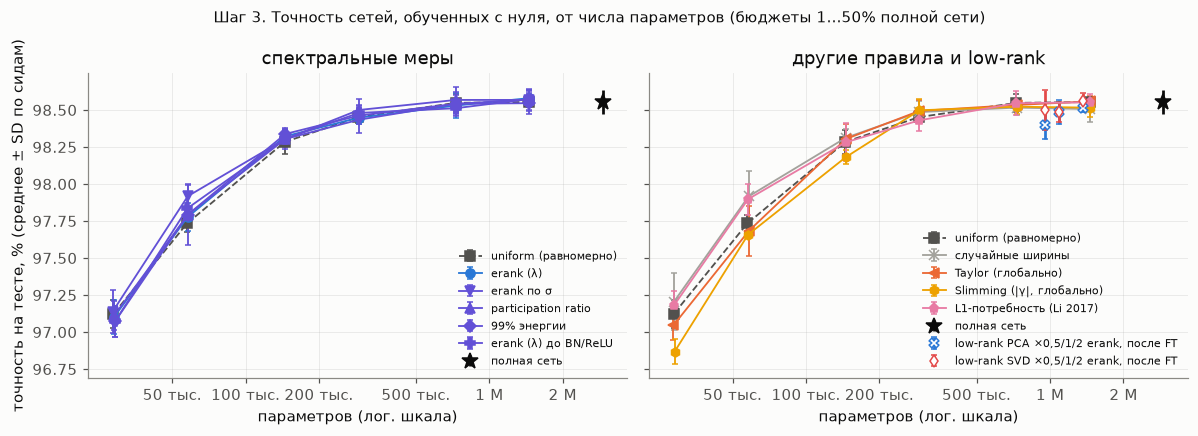

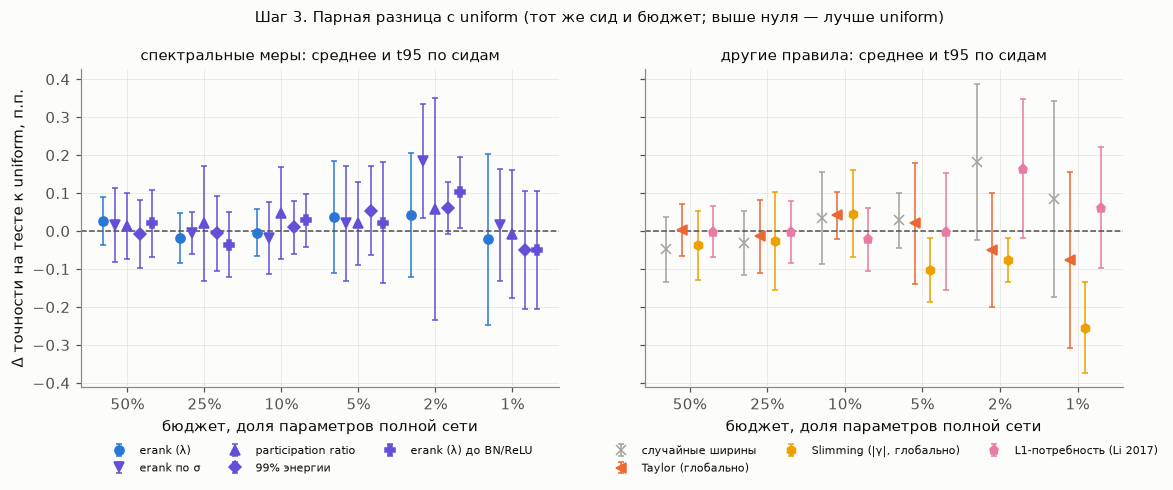

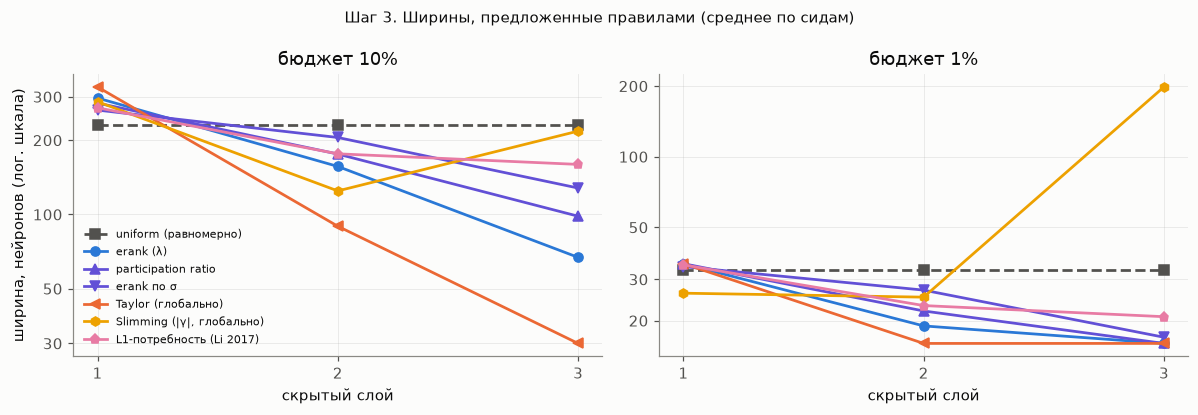

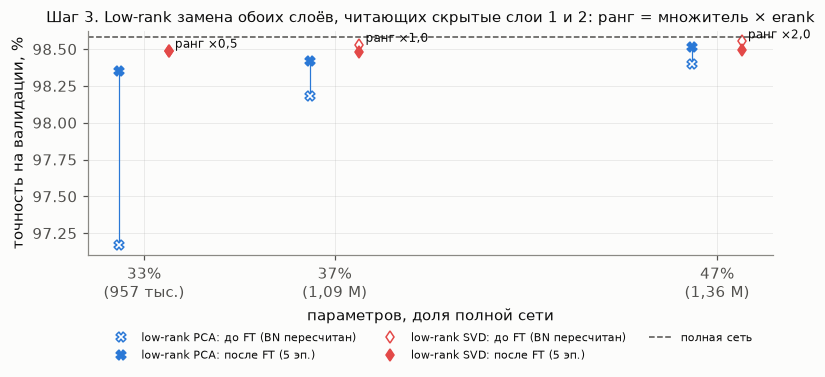

,50%,25%,10%,5%,2%,1%
"точность на тесте, %, среднее",,,,,,
uniform (равномерно),"98,55","98,55","98,45","98,28","97,73","97,12"
случайные ширины,"98,51","98,52","98,49","98,31","97,92","97,21"
erank (λ),"98,58","98,53","98,45","98,32","97,78","97,10"
erank по σ,"98,57","98,54","98,43","98,30","97,92","97,14"
participation ratio,"98,57","98,57","98,50","98,30","97,79","97,11"
99% энергии,"98,55","98,54","98,46","98,34","97,79","97,07"
erank (λ) до BN/ReLU,"98,57","98,51","98,48","98,31","97,84","97,07"
Taylor (глобально),"98,56","98,53","98,49","98,30","97,68","97,05"
"Slimming (|γ|, глобально)","98,52","98,52","98,50","98,18","97,66","96,87"


,50%,25%,10%,5%,2%,1%
ширины uniform,"[676, 676, 676]","[435, 435, 435]","[230, 230, 230]","[135, 135, 135]","[62, 62, 62]","[33, 33, 33]"


**Вывод шага 3.** Uniform по бюджетам 50%, 25%, 10%, 5%, 2%, 1%: 98,55 / 98,55 / 98,45 / 98,28 / 97,73 / 97,12% (полная сеть 98,55%). Наибольшая по модулю средняя разница спектральной меры с uniform: +0,18 п.п. (erank по σ, 2%). Интервал t95 (n = 5) не содержит нуля в 5 ячейках из 54: erank по σ 2% (лучше), erank (λ) до BN/ReLU 2% (лучше), Slimming (|γ|, глобально) 5% (хуже), Slimming (|γ|, глобально) 2% (хуже), Slimming (|γ|, глобально) 1% (хуже). Поправки на множественные сравнения нет: если эффекта нет, ноль случайно исключают около 5% ячеек (≈ 2,7 из 54). Low-rank PCA ×1: 37% параметров, val до FT −0,40 п.п. к полной сети, FT меняет val на +0,24 п.п. (test после FT 98,49%); low-rank SVD ×1: 37% параметров, val до FT −0,05 п.п. к полной сети, FT меняет val на −0,05 п.п. (test после FT 98,49%).

In [21]:
SPECTRAL = ["erank_energy", "erank_sv", "participation_ratio", "energy99", "erank_energy_pre"]
OTHERS = ["random", "taylor_global", "slimming_global", "l1_need"]
full_test = mean_sd([100 * r["test_acc"] for r in base_rows.values()])


def acc_curve(ax, m, rows=alloc_rows, key="test_acc"):
    pts = []
    for b in BUDGETS:
        sel = [r for r in rows if r["method"] == m and r["budget"] == b]
        if sel:
            pts.append((np.mean([r["params"] for r in sel]), *mean_sd([100 * r[key] for r in sel])))
    px, py, pe = zip(*pts)
    ax.errorbar(px, py, yerr=pe, capsize=2, lw=1.2, **sty(m))


fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, group, name in [(axes[0], SPECTRAL, "спектральные меры"), (axes[1], OTHERS, "другие правила и low-rank")]:
    for m in ["uniform"] + group:
        acc_curve(ax, m)
    ax.errorbar([BASE_PARAMS], [full_test[0]], yerr=[full_test[1]], color=PALETTE["teacher"], marker="*", ms=11,
                ls="none", label=LABELS["full"])
    ax.set(xscale="log", xlabel="параметров (лог. шкала)", title=name)
    ax.legend(fontsize=7.5)
for basis in ["pca", "svd"]:
    for mult in LOWRANK_MULTS:
        sel = [r for r in lowrank_rows if r["basis"] == basis and r["mult"] == mult]
        mu, sd = mean_sd([100 * r["test_acc"] for r in sel])
        s = sty(f"lowrank_{basis}")
        axes[1].errorbar([np.mean([r["params"] for r in sel])], [mu], yerr=[sd], color=s["color"], marker=s["marker"],
                         mfc="white", ls="none", capsize=2,
                         label=f"{s['label']} ×0,5/1/2 erank, после FT" if mult == LOWRANK_MULTS[0] else None)
axes[1].legend(fontsize=7.5)
for ax in axes:
    log_ticks(ax.xaxis)
axes[0].set_ylabel("точность на тесте, % (среднее ± SD по сидам)")
fig.suptitle("Шаг 3. Точность сетей, обученных с нуля, от числа параметров (бюджеты 1…50% полной сети)", fontsize=10)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
delta_panel(axes[0], alloc_rows, SPECTRAL, BUDGETS, "test_acc", 100, "Δ точности на тесте к uniform, п.п.",
            "спектральные меры: среднее и t95 по сидам")
delta_panel(axes[1], alloc_rows, OTHERS, BUDGETS, "test_acc", 100, "", "другие правила: среднее и t95 по сидам")
fig.suptitle("Шаг 3. Парная разница с uniform (тот же сид и бюджет; выше нуля — лучше uniform)", fontsize=10)
plt.tight_layout()
plt.show()

show_b = [b for b in (0.1, 0.01) if b in BUDGETS]
WIDTH_METHODS = ["uniform", "erank_energy", "participation_ratio", "erank_sv", "taylor_global", "slimming_global", "l1_need"]
fig, axes = plt.subplots(1, len(show_b), figsize=(11, 3.8), squeeze=False)
for ax, b in zip(axes[0], show_b):
    for m in WIDTH_METHODS:
        ws = np.array([r["widths"] for r in alloc_rows if r["method"] == m and r["budget"] == b])
        ax.plot([1, 2, 3], ws.mean(0), **sty(m))
    ax.set(yscale="log", xticks=[1, 2, 3], xlabel="скрытый слой", title=f"бюджет {100 * b:g}%")
    log_ticks(ax.yaxis)
axes[0][0].set_ylabel("ширина, нейронов (лог. шкала)")
axes[0][0].legend(fontsize=7.5)
fig.suptitle("Шаг 3. Ширины, предложенные правилами (среднее по сидам)", fontsize=10)
plt.tight_layout()
plt.show()

base_val = float(np.mean([100 * r["val_acc"] for r in base_rows.values()]))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
lr_params = {}
for basis, shift in [("pca", -0.006), ("svd", 0.006)]:   # PCA and SVD have equal sizes: shift them apart
    s = sty(f"lowrank_{basis}")
    for mult in LOWRANK_MULTS:
        sel = [r for r in lowrank_rows if r["basis"] == basis and r["mult"] == mult]
        lr_params[mult] = p = float(np.mean([r["params"] for r in sel]))
        xp = p / BASE_PARAMS + shift
        before, after = np.mean([100 * r["val_acc_before_ft"] for r in sel]), np.mean([100 * r["val_acc"] for r in sel])
        first = mult == LOWRANK_MULTS[0]
        ax.plot([xp, xp], [before, after], color=s["color"], lw=0.8)
        ax.plot([xp], [before], color=s["color"], marker=s["marker"], mfc="white", ls="none",
                label=f"{s['label']}: до FT (BN пересчитан)" if first else None)
        ax.plot([xp], [after], color=s["color"], marker=s["marker"], ls="none",
                label=f"{s['label']}: после FT ({FT_EPOCHS} эп.)" if first else None)
        if basis == "svd":
            ax.annotate(f"ранг ×{num(mult, 1)}", (xp, max(before, after)), fontsize=8, xytext=(4, 2),
                        textcoords="offset points")
ax.axhline(base_val, color=PALETTE["uniform"], ls="--", lw=1, label="полная сеть")
ax.set_xticks([p / BASE_PARAMS for p in lr_params.values()],
              [f"{num(100 * p / BASE_PARAMS, 0)}%\n({short(p)})" for p in lr_params.values()])
ax.set(xlabel="параметров, доля полной сети", ylabel="точность на валидации, %")
ax.set_title("Шаг 3. Low-rank замена обоих слоёв, читающих скрытые слои 1 и 2: ранг = множитель × erank",
             fontsize=10)
ax.legend(fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.3))
plt.tight_layout()
plt.show()

alloc_summ = {(m, b): paired_summary(paired(alloc_rows, m, b, "test_acc")) for m in ALLOC_METHODS[1:] for b in BUDGETS}
display(pd.DataFrame({LABELS[m]: [num(np.mean([100 * r["test_acc"] for r in alloc_rows if r["method"] == m and r["budget"] == b]), 2)
                                  for b in BUDGETS] for m in ALLOC_METHODS},
                     index=[f"{100 * b:g}%" for b in BUDGETS]).T.rename_axis("точность на тесте, %, среднее"))
display(pd.DataFrame({b_: [str(widths_for("uniform", b, SEEDS[0]))] for b_, b in zip([f"{100 * b:g}%" for b in BUDGETS], BUDGETS)},
                     index=["ширины uniform"]))
big = max(((m, b) for m in SPECTRAL for b in BUDGETS), key=lambda mb: abs(alloc_summ[mb]["mean_pp"]))
signif = [(m, b, ci_sign(alloc_summ[(m, b)])) for m in ALLOC_METHODS[1:] for b in BUDGETS if ci_sign(alloc_summ[(m, b)])]
n_alloc_cells = len(ALLOC_METHODS[1:]) * len(BUDGETS)
if len(SEEDS) < 2:
    signif_txt = f"При n = {len(SEEDS)} интервалы не оцениваются. "
elif signif:
    signif_txt = (f"Интервал t95 (n = {len(SEEDS)}) не содержит нуля в {len(signif)} ячейках из {n_alloc_cells}: "
                  + ", ".join(f"{LABELS[m]} {100 * b:g}% ({'лучше' if s > 0 else 'хуже'})" for m, b, s in signif)
                  + f". Поправки на множественные сравнения нет: если эффекта нет, ноль случайно исключают около 5% "
                  f"ячеек (≈ {num(0.05 * n_alloc_cells, 1)} из {n_alloc_cells}). ")
else:
    signif_txt = f"Ни в одной из {n_alloc_cells} ячеек интервал t95 не исключает ноль (n = {len(SEEDS)}). "
lr1 = {basis: [r for r in lowrank_rows if r["basis"] == basis and r["mult"] == 1] for basis in ["pca", "svd"]}
lr_txt = "; ".join(
    f"{LABELS['lowrank_' + basis]} ×1: {num(100 * np.mean([r['params'] for r in rows]) / BASE_PARAMS, 0)}% параметров, "
    f"val до FT {num(np.mean([100 * r['val_acc_before_ft'] for r in rows]) - base_val, 2, True)} п.п. к полной сети, "
    f"FT меняет val на {num(np.mean([100 * (r['val_acc'] - r['val_acc_before_ft']) for r in rows]), 2, True)} п.п. "
    f"(test после FT {num(np.mean([100 * r['test_acc'] for r in rows]), 2)}%)"
    for basis, rows in lr1.items() if rows) + "."
display(Markdown(
    f"**Вывод шага 3.** Uniform по бюджетам {', '.join(f'{100 * b:g}%' for b in BUDGETS)}: "
    f"{' / '.join(num(np.mean([100 * r['test_acc'] for r in alloc_rows if r['method'] == 'uniform' and r['budget'] == b]), 2) for b in BUDGETS)}% "
    f"(полная сеть {num(full_test[0])}%). Наибольшая по модулю средняя разница спектральной меры с uniform: "
    f"{num(alloc_summ[big]['mean_pp'], 2, True)} п.п. ({LABELS[big[0]]}, {100 * big[1]:g}%). "
    + signif_txt + cap(lr_txt)))

### Шаг 4. Срез из обученной сети + дообучение против обучения с нуля

Ширины от erank и от uniform при 25% и 5%; какие нейроны оставить, решают 5 критериев: случайно, L1 входящих весов,
|γ| BatchNorm базы, Taylor (20 батчей), дисперсия выхода (замена HRank: у нейрона MLP выход — число, а не карта).
Затем пересчёт BN, 5 эпох FT (lr 3e-4) и сравнение с той же архитектурой, обученной с нуля.

In [22]:
ft_rows = []
for seed in SEEDS:
    base = base_nets[seed]
    scores = {s: unit_scores(base, s, data, seed=seed) for s in SELECT_METHODS}
    for budget in FT_BUDGETS:
        for rule in FT_WIDTH_RULES:
            widths = widths_for(rule, budget, seed)
            sc = scratch_mnist(widths, seed)
            for select in SELECT_METHODS:
                row = cached(f"ft|{rule}|{budget}|{select}|s{seed}|e{EPOCHS}+{FT_EPOCHS}", lambda: surgery_row(
                    keep_units(base, [top_k(s, w) for s, w in zip(scores[select], widths)], x_fit), seed,
                    select=select, rule=rule, budget=budget, widths=widths))
                ft_rows.append({**row, "scratch_test_acc": sc["test_acc"], "scratch_val_acc": sc["val_acc"]})
    log(f"Шаг 4: сид {seed} готов")

2026-11-08 09:34:23  Шаг 4: сид 0 готов


2026-11-08 09:34:23  Шаг 4: сид 1 готов


2026-11-08 09:34:23  Шаг 4: сид 2 готов


2026-11-08 09:34:23  Шаг 4: сид 3 готов


2026-11-08 09:34:23  Шаг 4: сид 4 готов


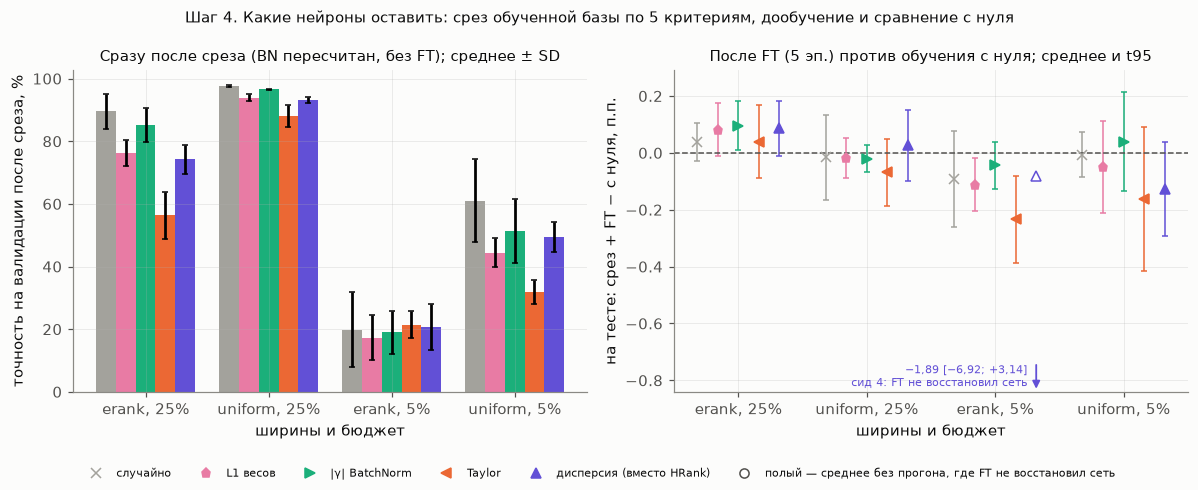

val без пересчёта BN val после среза  \
ширины, бюджет критерий                                                        
erank, 25%     случайно                                 29,9            89,6   
               L1 весов                                 33,0            76,3   
               |γ| BatchNorm                            49,2            85,2   
               Taylor                                   36,8            56,3   
               дисперсия (вместо HRank)                 25,6            74,2   
uniform, 25%   случайно                                 61,1            97,5   
               L1 весов                                 59,1            93,9   
               |γ| BatchNorm                            63,4            96,7   
               Taylor                                   56,0            88,1   
               дисперсия (вместо HRank)                 48,7            93,2   
erank, 5%      случайно                                 10,0            19,9   
               L1 весов                                 10,2            17,3   
               |γ| BatchNorm                            11,8            19,0   
               Taylor                                   10,0            21,4   
               дисперсия (вместо HRank)                 10,0            20,7   
uniform, 5%    случайно                                 10,0            61,1   
               L1 весов                                 10,8            44,4   
               |γ| BatchNorm                            10,8            51,4   
               Taylor                                   10,4            32,0   
               дисперсия (вместо HRank)                  9,3            49,5   

                                        test после FT test с нуля  \
ширины, бюджет критерий                                             
erank, 25%     случайно                         98,57       98,53   
               L1 весов                         98,61       98,53   
               |γ| BatchNorm                    98,63       98,53   
               Taylor                           98,57       98,53   
               дисперсия (вместо HRank)         98,62       98,53   
uniform, 25%   случайно                         98,53       98,55   
               L1 весов                         98,53       98,55   
               |γ| BatchNorm                    98,53       98,55   
               Taylor                           98,48       98,55   
               дисперсия (вместо HRank)         98,57       98,55   
erank, 5%      случайно                         98,23       98,32   
               L1 весов                         98,21       98,32   
               |γ| BatchNorm                    98,28       98,32   
               Taylor                           98,09       98,32   
               дисперсия (вместо HRank)         96,43       98,32   
uniform, 5%    случайно                         98,28       98,28   
               L1 весов                         98,23       98,28   
               |γ| BatchNorm                    98,32       98,28   
               Taylor                           98,12       98,28   
               дисперсия (вместо HRank)         98,16       98,28   

                                        FT − с нуля, п.п. [t95]  
ширины, бюджет критерий                                          
erank, 25%     случайно                    +0,04 [−0,03; +0,11]  
               L1 весов                    +0,08 [−0,01; +0,17]  
               |γ| BatchNorm               +0,10 [+0,01; +0,18]  
               Taylor                      +0,04 [−0,09; +0,17]  
               дисперсия (вместо HRank)    +0,09 [−0,01; +0,18]  
uniform, 25%   случайно                    −0,02 [−0,17; +0,13]  
               L1 весов                    −0,02 [−0,09; +0,05]  
               |γ| BatchNorm               −0,02 [−0,07; +0,03]  
               Taylor                      −0,07 [−0,19; +0,05]  
               дисперсия (вместо H

**Вывод шага 4.** Сразу после среза (точность на валидации, n = 5; парные t95 разницы с лидером по среднему): erank, 25% — лидер по среднему «случайно», от него не отличим «|γ| BatchNorm» (+4,4 [−1,7; +10,5] п.п.); uniform, 25% — «случайно», выше каждого из остальных (парный t95 выше нуля); erank, 5% — все 5 критериев 17–21%, попарные различия не отличимы от нуля; uniform, 5% — лидер по среднему «случайно», от него не отличимы «|γ| BatchNorm» (+9,7 [−3,0; +22,4] п.п.), «дисперсия (вместо HRank)» (+11,6 [−2,9; +26,1] п.п.). После FT разница с обучением тех же ширин с нуля по 20 ячейкам: средние — от −1,89 до +0,10 п.п., медианы — от −0,26 до +0,11 п.п.; интервал t95 выше нуля в 1, ниже нуля в 2 из 20 ячеек (n = 5). FT не восстановил сеть (FT − с нуля < −1 п.п.) в 1 прогоне из 100: erank, 5% — дисперсия (вместо HRank), сид 4 — 89,16% на тесте против 98,30% с нуля (−9,14 п.п.; на остальных сидах этой ячейки от −0,11 до −0,06). Без него средние по ячейкам — от −0,23 до +0,10 п.п. Эпохи обучения: срез + FT — 20 + 5, с нуля — 20.

In [23]:
groups = [(rule, b) for b in FT_BUDGETS for rule in FT_WIDTH_RULES]
gname = {g: f"{'erank' if g[0] == 'erank_energy' else g[0]}, {100 * g[1]:g}%" for g in groups}
FT_FAIL_PP = 1.0   # a run with FT − scratch below −1 p.p. is reported as a fine-tune that did not recover the net


def cell_rows(g, sel):
    return [r for r in ft_rows if (r["rule"], r["budget"]) == g and r["select"] == sel]


def ft_gap(r) -> float:
    """Test accuracy after slicing + FT minus the same widths trained from scratch on the same seed, p.p."""
    return 100 * (r["test_acc"] - r["scratch_test_acc"])


ft_summ = {(g, s): paired_summary([ft_gap(r) for r in cell_rows(g, s)]) for g in groups for s in SELECT_METHODS}
ft_failed = [r for r in ft_rows if ft_gap(r) < -FT_FAIL_PP]
fail_cells = {((r["rule"], r["budget"]), r["select"]) for r in ft_failed}
failed_ids = {id(r) for r in ft_failed}
ft_ok = {k: [ft_gap(r) for r in cell_rows(*k) if id(r) not in failed_ids] for k in ft_summ}
ft_ok_means = {k: float(np.mean(v)) for k, v in ft_ok.items() if v}   # cell means without the failed runs

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
x, w = np.arange(len(groups)), 0.8 / len(SELECT_METHODS)
# right panel: y range of the cells without a failed run (one off-scale cell must not flatten the other 19)
span = [0.0] + list(ft_ok_means.values()) + [y for k, v in ft_summ.items() if k not in fail_cells and v["n"]
                                              for y in [v["mean_pp"], *(v["ci95_pp"] or [])]]
pad = 0.12 * (max(span) - min(span)) or 0.1
ylo, yhi = min(span) - pad, max(span) + pad
room = 0.45 * (yhi - ylo)   # space for the note of an off-scale cell
ylo -= room * any(v["n"] and v["mean_pp"] < ylo for v in ft_summ.values())
yhi += room * any(v["n"] and v["mean_pp"] > yhi for v in ft_summ.values())
n_off = sum(bool(v["n"]) and not ylo <= v["mean_pp"] <= yhi for v in ft_summ.values())
for i, sel in enumerate(SELECT_METHODS):
    bs = bar_sty(sel)
    before = [mean_sd([100 * r["val_acc_before_ft"] for r in cell_rows(g, sel)]) for g in groups]
    axes[0].bar(x - 0.4 + w * (i + 0.5), [m for m, _ in before], w, yerr=[s for _, s in before], capsize=2,
                color=bs["color"])
    for j, g in enumerate(groups):
        st, xj = ft_summ[(g, sel)], x[j] - 0.4 + w * (i + 0.5)
        if not st["n"]:
            continue
        if (g, sel) in fail_cells and (g, sel) in ft_ok_means:   # hollow: the cell without its failed runs
            axes[1].plot([xj], [ft_ok_means[(g, sel)]], color=bs["color"], marker=MARKERS[sel], mfc="white", ls="none")
        if ylo <= st["mean_pp"] <= yhi:
            err = None if st["ci95_pp"] is None else [[st["mean_pp"] - st["ci95_pp"][0]], [st["ci95_pp"][1] - st["mean_pp"]]]
            axes[1].errorbar(xj, st["mean_pp"], yerr=err, color=bs["color"], marker=MARKERS[sel], ls="none",
                             capsize=2, lw=1)
            continue
        below = st["mean_pp"] < ylo   # off the scale: an arrow at the edge and the numbers next to it
        edge, step = (ylo, 1) if below else (yhi, -1)
        axes[1].annotate("", xy=(xj, edge), xytext=(xj, edge + step * 0.3 * room),
                         arrowprops={"arrowstyle": "-|>", "color": bs["color"], "lw": 1.2})
        if n_off > 1:   # several cells off the scale: only the mean, written along the arrow
            axes[1].annotate(num(st["mean_pp"], 1, True), (xj, edge + step * 0.32 * room), ha="center",
                             va="bottom" if below else "top", rotation=90, fontsize=7, color=bs["color"])
            continue
        note = num(st["mean_pp"], 2, True) + ("" if st["ci95_pp"] is None else
                                               f" [{num(st['ci95_pp'][0], 2, True)}; {num(st['ci95_pp'][1], 2, True)}]")
        seeds_failed = [r["seed"] for r in ft_failed if ((r["rule"], r["budget"]), r["select"]) == (g, sel)]
        if seeds_failed:
            note += f"\n{'сид' if len(seeds_failed) == 1 else 'сиды'} {', '.join(map(str, seeds_failed))}: FT не восстановил сеть"
        axes[1].annotate(note, (xj, edge + step * 0.15 * room), xytext=(-6, 0), textcoords="offset points", ha="right",
                         va="center", fontsize=7, color=bs["color"])
axes[0].set(ylabel="точность на валидации после среза, %", xlabel="ширины и бюджет")
axes[0].set_xticks(x, [gname[g] for g in groups])
axes[0].set_title("Сразу после среза (BN пересчитан, без FT); среднее ± SD", fontsize=10)
axes[1].axhline(0, color=PALETTE["uniform"], ls="--", lw=1)
axes[1].set(ylabel="на тесте: срез + FT − с нуля, п.п.", xlabel="ширины и бюджет", ylim=(ylo, yhi))
axes[1].set_xticks(x, [gname[g] for g in groups])
axes[1].set_title(f"После FT ({FT_EPOCHS} эп.) против обучения с нуля; среднее и t95", fontsize=10)
handles = [plt.Line2D([], [], color=bar_sty(s)["color"], marker=MARKERS[s], ls="none", label=SEL_LABELS[s])
           for s in SELECT_METHODS]
if fail_cells & set(ft_ok_means):
    handles.append(plt.Line2D([], [], color=PALETTE["uniform"], marker="o", mfc="white", ls="none",
                              label="полый — среднее без прогона, где FT не восстановил сеть"))
fig.legend(handles=handles, fontsize=7.5, ncol=len(handles), loc="lower center")
fig.suptitle("Шаг 4. Какие нейроны оставить: срез обученной базы по 5 критериям, дообучение и сравнение с нуля",
             fontsize=10)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

tab = []
for g in groups:
    for sel in SELECT_METHODS:
        rs = cell_rows(g, sel)
        tab.append({"ширины, бюджет": gname[g], "критерий": SEL_LABELS[sel],
                    "val без пересчёта BN": num(np.mean([100 * r["val_acc_no_bn_recal"] for r in rs]), 1),
                    "val после среза": num(np.mean([100 * r["val_acc_before_ft"] for r in rs]), 1),
                    "test после FT": num(np.mean([100 * r["test_acc"] for r in rs]), 2),
                    "test с нуля": num(np.mean([100 * r["scratch_test_acc"] for r in rs]), 2),
                    "FT − с нуля, п.п. [t95]": ci_text(ft_summ[(g, sel)])})
display(pd.DataFrame(tab).set_index(["ширины, бюджет", "критерий"]))
best_sel = {g: max(SELECT_METHODS, key=lambda s: np.mean([r["val_acc_before_ft"] for r in cell_rows(g, s)]))
            for g in groups}


def val_gap(g, a, b) -> dict:
    """Paired difference of the validation accuracy right after slicing, criterion a − criterion b, p.p."""
    va = {r["seed"]: r["val_acc_before_ft"] for r in cell_rows(g, a)}
    vb = {r["seed"]: r["val_acc_before_ft"] for r in cell_rows(g, b)}
    return paired_summary([100 * (va[s] - vb[s]) for s in va if s in vb])


def leader_text(g) -> str:
    """The criterion with the best mean right after slicing, and which criteria its paired t95 does not separate."""
    best = best_sel[g]
    if len(SEEDS) < 2:
        return f"{gname[g]} — «{SEL_LABELS[best]}» по среднему (при n = 1 интервалы не оцениваются)"
    pairs = [(a, b) for k, a in enumerate(SELECT_METHODS) for b in SELECT_METHODS[k + 1:]]
    if all(ci_sign(val_gap(g, a, b)) == 0 for a, b in pairs):
        vals = [np.mean([100 * r["val_acc_before_ft"] for r in cell_rows(g, s)]) for s in SELECT_METHODS]
        return (f"{gname[g]} — все {len(SELECT_METHODS)} критериев {num(min(vals), 0)}–{num(max(vals), 0)}%, "
                "попарные различия не отличимы от нуля")
    tied = [s for s in SELECT_METHODS if s != best and ci_sign(val_gap(g, best, s)) <= 0]
    if not tied:
        return f"{gname[g]} — «{SEL_LABELS[best]}», выше каждого из остальных (парный t95 выше нуля)"
    return (f"{gname[g]} — лидер по среднему «{SEL_LABELS[best]}», от него не {'отличим' if len(tied) == 1 else 'отличимы'} "
            + ", ".join(f"«{SEL_LABELS[s]}» ({ci_text(val_gap(g, best, s), 1)} п.п.)" for s in tied))


def fail_item(r) -> str:
    g = (r["rule"], r["budget"])
    rest = [ft_gap(o) for o in cell_rows(g, r["select"]) if o["seed"] != r["seed"]]
    rest_txt = f"; на остальных сидах этой ячейки от {num(min(rest), 2, True)} до {num(max(rest), 2, True)}" if rest else ""
    return (f"{gname[g]} — {SEL_LABELS[r['select']]}, сид {r['seed']} — {num(100 * r['test_acc'], 2)}% на тесте против "
            f"{num(100 * r['scratch_test_acc'], 2)}% с нуля ({num(ft_gap(r), 2, True)} п.п.{rest_txt})")


signs = [ci_sign(v) for v in ft_summ.values()]
means = [v["mean_pp"] for v in ft_summ.values()]
medians = [float(np.median([ft_gap(r) for r in cell_rows(*k)])) for k in ft_summ]
fail_txt = ""
if ft_failed:
    n_f = len(ft_failed)
    fail_txt = (f" FT не восстановил сеть (FT − с нуля < −{num(FT_FAIL_PP, 0)} п.п.) в {n_f} "
                f"{'прогоне' if n_f % 10 == 1 and n_f % 100 != 11 else 'прогонах'} из {len(ft_rows)}: "
                + "; ".join(fail_item(r) for r in ft_failed[:3])
                + (f"; и ещё {len(ft_failed) - 3}" if len(ft_failed) > 3 else "") + ".")
    if ft_ok_means:
        fail_txt += (f" Без {'него' if len(ft_failed) == 1 else 'них'} средние по ячейкам — от "
                     f"{num(min(ft_ok_means.values()), 2, True)} до {num(max(ft_ok_means.values()), 2, True)} п.п.")
display(Markdown(
    f"**Вывод шага 4.** Сразу после среза (точность на валидации, n = {len(SEEDS)}; парные t95 разницы с лидером по "
    "среднему): " + "; ".join(leader_text(g) for g in groups)
    + f". После FT разница с обучением тех же ширин с нуля по {len(ft_summ)} ячейкам: средние — от "
    f"{num(min(means), 2, True)} до {num(max(means), 2, True)} п.п., медианы — от {num(min(medians), 2, True)} до "
    f"{num(max(medians), 2, True)} п.п.; интервал t95 выше нуля в {signs.count(1)}, ниже нуля в {signs.count(-1)} "
    f"из {len(signs)} ячеек (n = {len(SEEDS)})." + fail_txt
    + f" Эпохи обучения: срез + FT — {EPOCHS} + {FT_EPOCHS}, с нуля — {EPOCHS}."))

### Шаг 5. Итерации: сходится ли процедура

(a) Бюджет 10%: erank сети прошлого раунда → ширины → обучение с нуля, 4 раунда (раунд 1 — erank базы);
сходимость — средний относительный сдвиг ширин между раундами. (b) Буквальный повтор шагов 2–4 с уменьшением
бюджета 50 → 25 → 10 → 5%: erank дообученной сети прошлого раунда → ширины (не шире прошлых) → срез L1 → BN →
5 эпох FT; те же ширины обучаются и с нуля. Сеть раунда r со срезом в сумме обучалась 20 + 5r эпох, сеть с нуля — 20.

In [24]:
iter_rows = []
for seed in SEEDS:
    target = int(ITER_BUDGET * BASE_PARAMS)
    eranks, prev = [m["erank_energy"] for m in base_rows[seed]["layers"]], None
    for r in range(1, ITER_ROUNDS + 1):
        widths = match_budget(eranks, target, IN_DIM, 10, BASE_WIDTHS, FLOOR)   # the full net sets caps and costs
        sc = scratch_mnist(widths, seed)
        change = None if prev is None else float(np.mean([abs(w - p) / p for w, p in zip(widths, prev)]))
        iter_rows.append({"round": r, "seed": seed, "widths": widths, "eranks": eranks, "change": change,
                          "test_acc": sc["test_acc"], "val_acc": sc["val_acc"]})
        eranks, prev = sc["erank"], widths   # the next round allocates by the new network's erank
    log(f"Шаг 5a: сид {seed}: ширины по раундам {[r['widths'] for r in iter_rows if r['seed'] == seed]}")
iter_uniform = [scratch_mnist(widths_for("uniform", ITER_BUDGET, s), s)["test_acc"] for s in SEEDS]

2026-11-08 09:34:23  Шаг 5a: сид 0: ширины по раундам [[297, 156, 67], [300, 148, 64], [302, 143, 64], [303, 142, 64]]


2026-11-08 09:34:23  Шаг 5a: сид 1: ширины по раундам [[297, 156, 67], [301, 147, 64], [301, 147, 63], [298, 154, 64]]


2026-11-08 09:34:23  Шаг 5a: сид 2: ширины по раундам [[296, 158, 66], [302, 145, 62], [305, 137, 63], [306, 134, 62]]


2026-11-08 09:34:23  Шаг 5a: сид 3: ширины по раундам [[296, 158, 68], [298, 155, 62], [304, 139, 64], [305, 136, 65]]


2026-11-08 09:34:23  Шаг 5a: сид 4: ширины по раундам [[297, 155, 67], [300, 149, 64], [303, 142, 63], [305, 136, 64]]


In [25]:
prog_rows = []
for seed in SEEDS:
    prev = base_nets[seed]
    for r, budget in enumerate(PROG_BUDGETS, 1):
        chain = "-".join(f"{b:g}" for b in PROG_BUDGETS[:r])
        eranks = [m["erank_energy"] for m in layer_metrics(prev, data["x_val"])]
        widths = match_budget(eranks, int(budget * BASE_PARAMS), IN_DIM, 10, prev.widths, FLOOR)  # capped by prev
        run_id = f"prog|{chain}|s{seed}|e{EPOCHS}+{FT_EPOCHS}"
        saved = stored().get(run_id, {}).get("widths")
        if saved is not None and saved != widths:  # a resumed run rebuilds the stored net, not a recomputed shape
            log(f"Шаг 5b: сид {seed}, раунд {r}: пересчитанные ширины {widths} ≠ сохранённых {saved}; беру сохранённые")
            widths = saved

        def fit():
            small = keep_units(prev, [top_k(s, w) for s, w in zip(unit_scores(prev, "l1"), widths)], x_fit)
            row = surgery_row(small, seed, round=r, budget=budget, widths=widths, eranks=eranks,
                              prev_widths=list(prev.widths), total_epochs=EPOCHS + r * FT_EPOCHS)
            return small, {**row, "epochs": row["total_epochs"]}  # finetune_and_log writes EPOCHS + FT_EPOCHS
        net, row = trained(run_id, lambda: MLP(IN_DIM, widths, 10).to(DEVICE), fit)
        sc = scratch_mnist(widths, seed)
        prog_rows.append({**row, "round": r, "seed": seed, "scratch_test_acc": sc["test_acc"]})
        prev = net
    log(f"Шаг 5b: сид {seed}: ширины {[r['widths'] for r in prog_rows if r['seed'] == seed]}")

2026-11-08 09:34:24  Шаг 5b: сид 0: ширины [[1011, 532, 228], [635, 310, 98], [308, 138, 42], [167, 69, 25]]


2026-11-08 09:34:25  Шаг 5b: сид 1: ширины [[1013, 531, 226], [642, 299, 100], [310, 132, 42], [169, 64, 24]]


2026-11-08 09:34:25  Шаг 5b: сид 2: ширины [[1009, 536, 223], [641, 301, 100], [309, 134, 42], [168, 65, 25]]


2026-11-08 09:34:26  Шаг 5b: сид 3: ширины [[1008, 535, 229], [640, 302, 99], [309, 136, 42], [168, 67, 25]]


2026-11-08 09:34:27  Шаг 5b: сид 4: ширины [[1015, 528, 228], [643, 298, 98], [309, 134, 41], [168, 65, 25]]


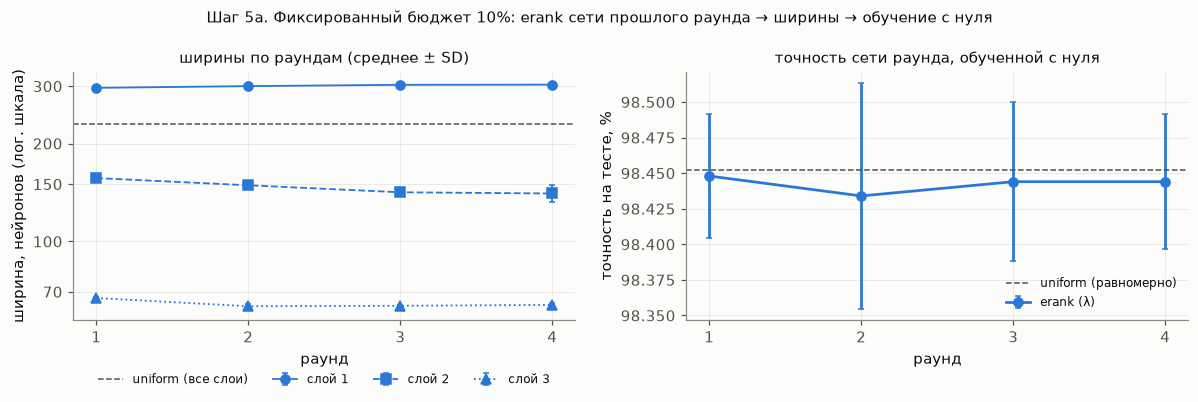

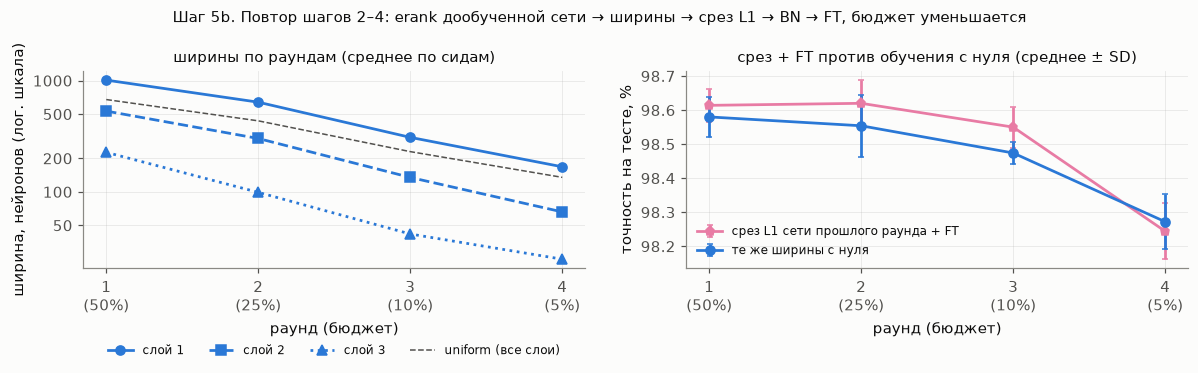

,,ширины,"erank, по которому выбраны","сдвиг ширин, %","test, %"
раунд,сид,,,,
1,0,"[297, 156, 67]","[86.4, 45.4, 19.4]",н/д,"98,42"
2,0,"[300, 148, 64]","[57.7, 28.4, 12.1]","3,5","98,44"
3,0,"[302, 143, 64]","[57.3, 27.1, 12.1]","1,3","98,49"
4,0,"[303, 142, 64]","[58.1, 27.2, 12.2]","0,3","98,50"
1,1,"[297, 156, 67]","[85.8, 44.9, 19.1]",н/д,"98,41"
2,1,"[301, 147, 64]","[58.3, 28.4, 12.3]","3,9","98,31"
3,1,"[301, 147, 63]","[58.4, 28.4, 12.2]","0,5","98,38"
4,1,"[298, 154, 64]","[57.7, 29.7, 12.3]","2,4","98,37"
1,2,"[296, 158, 66]","[86.6, 46.0, 19.1]",н/д,"98,50"


,,бюджет,ширины,val после среза,test после FT,test с нуля
раунд,сид,,,,,
1,0,50%,"[1011, 532, 228]","96,4","98,64","98,52"
2,0,25%,"[635, 310, 98]","96,4","98,72","98,62"
3,0,10%,"[308, 138, 42]","80,6","98,55","98,45"
4,0,5%,"[167, 69, 25]","83,2","98,17","98,22"
1,1,50%,"[1013, 531, 226]","95,6","98,64","98,66"
2,1,25%,"[642, 299, 100]","97,2","98,60","98,62"
3,1,10%,"[310, 132, 42]","90,6","98,50","98,50"
4,1,5%,"[169, 64, 24]","76,8","98,16","98,31"
1,2,50%,"[1009, 536, 223]","93,8","98,53","98,56"


**Вывод шага 5.** (a) Средний относительный сдвиг ширин между раундами: 1→2: 4,0%, 2→3: 2,4%, 3→4: 1,5% — сдвиг уменьшается: с 4,0% до 1,5%; в последнем раунде ширины не изменились у 0 из 5 сидов; итоговые ширины (сид 0): [303, 142, 64]. Точность на тесте: раунд 1 98,45%, раунд 4 98,44% (раунд 4 − раунд 1: −0,00 [−0,08; +0,07] п.п., n = 5), uniform 98,45%. (b) Срез + FT − те же ширины с нуля, п.п. по раундам: 50% +0,03 [−0,06; +0,13], 25% +0,07 [−0,00; +0,14], 10% +0,08 [−0,03; +0,19], 5% −0,03 [−0,13; +0,07]. Сеть раунда r со срезом обучалась 20 + r·5 эпох (база и r дообучений), сеть с нуля — 20.

In [26]:
rounds = list(range(1, ITER_ROUNDS + 1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for l, mk in zip(range(3), ["o", "s", "^"]):
    ws = np.array([[r["widths"][l] for r in iter_rows if r["seed"] == s] for s in SEEDS])
    sd = ws.std(0, ddof=1) if len(SEEDS) > 1 else None
    axes[0].errorbar(rounds, ws.mean(0), yerr=sd, color=PALETTE["erank"], marker=mk, capsize=2, lw=1.2,
                     ls=["-", "--", ":"][l], label=f"слой {l + 1}")
axes[0].axhline(widths_for("uniform", ITER_BUDGET, SEEDS[0])[0], color=PALETTE["uniform"], ls="--", lw=1,
                label="uniform (все слои)")
axes[0].set(yscale="log", xticks=rounds, xlabel="раунд", ylabel="ширина, нейронов (лог. шкала)")
log_ticks(axes[0].yaxis)
axes[0].set_title("ширины по раундам (среднее ± SD)", fontsize=10)
axes[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17))
acc = np.array([[100 * r["test_acc"] for r in iter_rows if r["seed"] == s] for s in SEEDS])
axes[1].errorbar(rounds, acc.mean(0), yerr=acc.std(0, ddof=1) if len(SEEDS) > 1 else None, capsize=2, **sty("erank_energy"))
axes[1].axhline(100 * np.mean(iter_uniform), color=PALETTE["uniform"], ls="--", lw=1, label=LABELS["uniform"])
axes[1].set(xticks=rounds, xlabel="раунд", ylabel="точность на тесте, %")
axes[1].set_title("точность сети раунда, обученной с нуля", fontsize=10)
axes[1].legend(fontsize=8)
fig.suptitle(f"Шаг 5a. Фиксированный бюджет {100 * ITER_BUDGET:g}%: erank сети прошлого раунда → ширины → обучение с нуля",
             fontsize=10)
plt.tight_layout()
plt.show()

prounds = list(range(1, len(PROG_BUDGETS) + 1))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for l, mk in zip(range(3), ["o", "s", "^"]):
    ws = np.array([[r["widths"][l] for r in prog_rows if r["seed"] == s] for s in SEEDS])
    axes[0].plot(prounds, ws.mean(0), color=PALETTE["erank"], marker=mk, ls=["-", "--", ":"][l], label=f"слой {l + 1}")
axes[0].plot(prounds, [widths_for("uniform", b, SEEDS[0])[0] for b in PROG_BUDGETS], color=PALETTE["uniform"],
             ls="--", lw=1, label="uniform (все слои)")
axes[0].set(yscale="log", xlabel="раунд (бюджет)", ylabel="ширина, нейронов (лог. шкала)")
log_ticks(axes[0].yaxis)
axes[0].set_xticks(prounds, [f"{r}\n({100 * b:g}%)" for r, b in zip(prounds, PROG_BUDGETS)])
axes[0].set_title("ширины по раундам (среднее по сидам)", fontsize=10)
axes[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.33))
for key, name, kw in [("test_acc", "срез L1 сети прошлого раунда + FT", sty("l1_need") | {"label": None}),
                      ("scratch_test_acc", "те же ширины с нуля", sty("erank_energy") | {"label": None})]:
    a = np.array([[100 * r[key] for r in prog_rows if r["seed"] == s] for s in SEEDS])
    axes[1].errorbar(prounds, a.mean(0), yerr=a.std(0, ddof=1) if len(SEEDS) > 1 else None, capsize=2,
                     **(kw | {"label": name}))
axes[1].set(xlabel="раунд (бюджет)", ylabel="точность на тесте, %")
axes[1].set_xticks(prounds, [f"{r}\n({100 * b:g}%)" for r, b in zip(prounds, PROG_BUDGETS)])
axes[1].set_title("срез + FT против обучения с нуля (среднее ± SD)", fontsize=10)
axes[1].legend(fontsize=8)
fig.suptitle("Шаг 5b. Повтор шагов 2–4: erank дообученной сети → ширины → срез L1 → BN → FT, бюджет уменьшается",
             fontsize=10)
plt.tight_layout()
plt.show()

chg = {r: [x["change"] for x in iter_rows if x["round"] == r] for r in rounds[1:]}
display(pd.DataFrame([{"раунд": r["round"], "сид": r["seed"], "ширины": r["widths"],
                       "erank, по которому выбраны": [round(e, 1) for e in r["eranks"]],
                       "сдвиг ширин, %": num(None if r["change"] is None else 100 * r["change"], 1),
                       "test, %": num(100 * r["test_acc"], 2)} for r in iter_rows]
                     ).set_index(["раунд", "сид"]))
display(pd.DataFrame([{"раунд": r["round"], "бюджет": f"{100 * r['budget']:g}%", "сид": r["seed"], "ширины": r["widths"],
                       "val после среза": num(100 * r["val_acc_before_ft"], 1), "test после FT": num(100 * r["test_acc"], 2),
                       "test с нуля": num(100 * r["scratch_test_acc"], 2)} for r in prog_rows]).set_index(["раунд", "сид"]))
gap = {r: paired_summary([100 * (x["test_acc"] - x["scratch_test_acc"]) for x in prog_rows if x["round"] == r]) for r in prounds}
shift = {r: 100 * float(np.mean(v)) for r, v in chg.items()}   # mean relative width change, %
last_r = rounds[-1]
settled = sum(next(x["change"] for x in iter_rows if x["seed"] == s and x["round"] == last_r) == 0 for s in SEEDS)
iter_gap = paired_summary([100 * (next(x["test_acc"] for x in iter_rows if x["seed"] == s and x["round"] == last_r)
                                  - next(x["test_acc"] for x in iter_rows if x["seed"] == s and x["round"] == 1))
                           for s in SEEDS])
first_s, last_s = shift[rounds[1]], shift[last_r]
trend = ("" if len(shift) < 2 else f" — сдвиг {'уменьшается' if last_s < first_s else 'не уменьшается'}: с "
         f"{num(first_s, 1)}% до {num(last_s, 1)}%")
display(Markdown(
    f"**Вывод шага 5.** (a) Средний относительный сдвиг ширин между раундами: "
    + ", ".join(f"{r - 1}→{r}: {num(v, 1)}%" for r, v in shift.items())
    + f"{trend}; в последнем раунде ширины не изменились у {settled} из {len(SEEDS)} сидов; итоговые ширины "
    f"(сид {SEEDS[0]}): {[x['widths'] for x in iter_rows if x['seed'] == SEEDS[0]][-1]}. Точность на тесте: раунд 1 "
    f"{num(acc.mean(0)[0], 2)}%, раунд {last_r} {num(acc.mean(0)[-1], 2)}% (раунд {last_r} − раунд 1: "
    f"{ci_text(iter_gap)} п.п., n = {len(SEEDS)}), uniform {num(100 * np.mean(iter_uniform), 2)}%. "
    f"(b) Срез + FT − те же ширины с нуля, п.п. по раундам: "
    + ", ".join(f"{100 * b:g}% {ci_text(gap[r])}" for r, b in zip(prounds, PROG_BUDGETS))
    + f". Сеть раунда r со срезом обучалась {EPOCHS} + r·{FT_EPOCHS} эпох (база и r дообучений), сеть с нуля — "
    f"{EPOCHS}."))

### Размер, MACs и время инференса

Параметры, умножения-сложения на один вход и медиана 30 замеров после 5 прогревов: CPU fp32 (4 потока, батч 32 и 1)
и GPU bf16 (батч 512). Сети: полная, все сети шага 3 сида 0 и low-rank ×1; веса на время не влияют.

In [27]:
s0 = SEEDS[0]
nets = [("full", 1.0, MLP(IN_DIM, BASE_WIDTHS, 10))]   # time does not depend on the weights
nets += [(r["method"], r["budget"], MLP(IN_DIM, r["widths"], 10)) for r in alloc_rows if r["seed"] == s0]
erank0 = [m["erank_energy"] for m in base_rows[s0]["layers"]]
for basis in ["pca", "svd"]:
    nets.append((f"lowrank_{basis}", "×1", lowrank(base_nets[s0], [max(FLOOR, round(r)) for r in erank0[:-1]] + [None],
                                                   basis, x_fit)))
lat_rows, threads = [], torch.get_num_threads()
torch.set_num_threads(LAT_THREADS)
try:
    lat_meta = latency_metadata(DEVICE)
    for method, budget, model in nets:
        model = model.cpu()
        lat_rows.append({"method": method, "budget": budget, "params": model_params(model), "macs": count_macs(model),
                         "cpu_ms_b32": latency_ms(model, "cpu", 32, LAT_REPEATS),
                         "cpu_ms_b1": latency_ms(model, "cpu", 1, LAT_REPEATS),
                         "gpu_ms_b512": latency_ms(model.to("cuda"), "cuda", LAT_GPU_BATCH, LAT_REPEATS)
                         if DEVICE == "cuda" else float("nan")})
finally:
    torch.set_num_threads(threads)  # restore the thread count of the session
log(f"время инференса измерено, сетей: {len(lat_rows)}; {LAT_THREADS} потока CPU, медиана {LAT_REPEATS} повторов")

2026-11-08 09:34:30  время инференса измерено, сетей: 63; 4 потока CPU, медиана 30 повторов


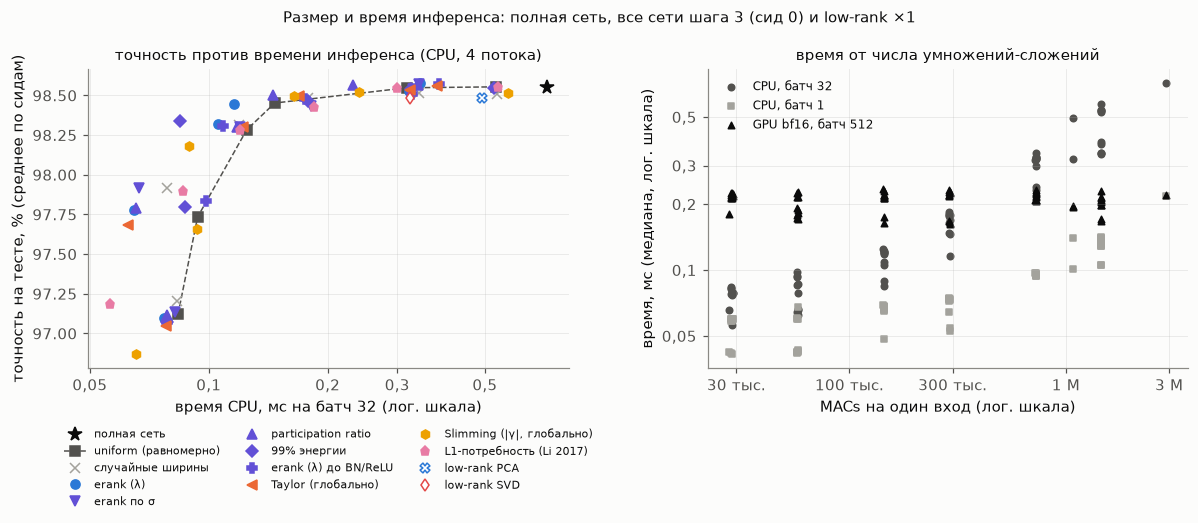

,,параметров,MACs,"CPU b32, мс","CPU b1, мс","GPU b512, мс","test, %"
сеть,бюджет,,,,,,
полная сеть,100%,2919434,2910208,"0,717","0,2182","0,2205","98,55"
uniform (равномерно),50%,1456790,1450696,"0,535","0,1289","0,1980","98,55"
erank (λ),50%,1459375,1454052,"0,342","0,1053","0,1679","98,58"
uniform (равномерно),25%,727765,723840,"0,317","0,0973","0,2095","98,55"
erank (λ),25%,729223,725985,"0,321","0,0950","0,2078","98,53"
uniform (равномерно),10%,290500,288420,"0,147","0,0720","0,2211","98,45"
erank (λ),10%,291872,290302,"0,115","0,0529","0,1636","98,45"
uniform (равномерно),5%,144865,143640,"0,125","0,0690","0,2348","98,28"
erank (λ),5%,145357,144492,"0,105","0,0681","0,2128","98,32"


**Вывод.** Spearman(MACs, время): CPU батч 32 — 0,93, CPU батч 1 — 0,90, GPU — −0,09. У MLP MACs/параметры = 0,973…0,997, поэтому бюджет по параметрам — это и бюджет по MACs. Время CPU (батч 32) полной сети 0,717 мс; erank / uniform при одном бюджете: 50% — 0,64, 25% — 1,01, 10% — 0,79, 5% — 0,84, 2% — 0,69, 1% — 0,92. Замер: 4 потока CPU, fp32; GPU в bf16; медиана 30 повторов после 5 прогревов.

In [28]:
def mean_test(method, budget):
    if method == "full":
        return float(np.mean([100 * r["test_acc"] for r in base_rows.values()]))
    if method.startswith("lowrank"):
        return float(np.mean([100 * r["test_acc"] for r in lowrank_rows if r["method"] == method and r["mult"] == 1]))
    return float(np.mean([100 * r["test_acc"] for r in alloc_rows if r["method"] == method and r["budget"] == budget]))


for r in lat_rows:
    r["test_acc"] = mean_test(r["method"], r["budget"])
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for m in ["full"] + ALLOC_METHODS + ["lowrank_pca", "lowrank_svd"]:
    sel = sorted([r for r in lat_rows if r["method"] == m], key=lambda r: r["cpu_ms_b32"])
    s = sty(m)
    axes[0].plot([r["cpu_ms_b32"] for r in sel], [r["test_acc"] for r in sel], color=s["color"], marker=s["marker"],
                 ls=s["ls"] if m == "uniform" else "none", lw=1, ms=9 if m == "full" else 6, label=s["label"],
                 mfc="white" if m.startswith("lowrank") else s["color"])   # low-rank hollow, as on the Step 3 plots
axes[0].set(xscale="log", xlabel="время CPU, мс на батч 32 (лог. шкала)", ylabel="точность на тесте, % (среднее по сидам)")
log_ticks(axes[0].xaxis)
axes[0].set_title(f"точность против времени инференса (CPU, {LAT_THREADS} потока)", fontsize=10)
axes[0].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.17))
macs = np.array([r["macs"] for r in lat_rows])
for key, color, mk, name in [("cpu_ms_b32", PALETTE["uniform"], "o", "CPU, батч 32"),
                             ("cpu_ms_b1", PALETTE["random"], "s", "CPU, батч 1"),
                             ("gpu_ms_b512", PALETTE["teacher"], "^", f"GPU bf16, батч {LAT_GPU_BATCH}")]:
    vals = np.array([r[key] for r in lat_rows], dtype=float)
    if not np.isnan(vals).all():
        axes[1].scatter(macs, vals, color=color, marker=mk, s=18, label=name)
axes[1].set(xscale="log", yscale="log", xlabel="MACs на один вход (лог. шкала)", ylabel="время, мс (медиана, лог. шкала)")
log_ticks(axes[1].xaxis, max_ticks=5)
log_ticks(axes[1].yaxis)
axes[1].set_title("время от числа умножений-сложений", fontsize=10)
axes[1].legend(fontsize=8)
fig.suptitle("Размер и время инференса: полная сеть, все сети шага 3 (сид 0) и low-rank ×1", fontsize=10)
plt.tight_layout()
plt.show()

rho_lat = {k: float("nan") if any(math.isnan(r[k]) for r in lat_rows)
           else spearman([r["macs"] for r in lat_rows], [r[k] for r in lat_rows])
           for k in ("cpu_ms_b32", "cpu_ms_b1", "gpu_ms_b512")}
key_rows = [r for r in lat_rows if r["method"] in ("full", "uniform", "erank_energy", "lowrank_pca", "lowrank_svd")]
display(pd.DataFrame([{"сеть": LABELS[r["method"]], "бюджет": r["budget"] if isinstance(r["budget"], str) else f"{100 * r['budget']:g}%",
                       "параметров": r["params"], "MACs": r["macs"], "CPU b32, мс": num(r["cpu_ms_b32"], 3),
                       "CPU b1, мс": num(r["cpu_ms_b1"], 4), "GPU b512, мс": num(r["gpu_ms_b512"], 4),
                       "test, %": num(r["test_acc"], 2)} for r in key_rows]).set_index(["сеть", "бюджет"]))
ratio = [r["macs"] / r["params"] for r in lat_rows]
full = next(r for r in lat_rows if r["method"] == "full")
uni = {r["budget"]: r for r in lat_rows if r["method"] == "uniform"}
era = {r["budget"]: r for r in lat_rows if r["method"] == "erank_energy"}
display(Markdown(
    f"**Вывод.** Spearman(MACs, время): CPU батч 32 — {num(rho_lat['cpu_ms_b32'])}, CPU батч 1 — "
    f"{num(rho_lat['cpu_ms_b1'])}, GPU — {num(rho_lat['gpu_ms_b512'])}. У MLP MACs/параметры = "
    f"{num(min(ratio), 3)}…{num(max(ratio), 3)}, поэтому бюджет по параметрам — это и бюджет по MACs. Время CPU (батч 32) "
    f"полной сети {num(full['cpu_ms_b32'], 3)} мс; erank / uniform при одном бюджете: "
    + ", ".join(f"{100 * b:g}% — {num(era[b]['cpu_ms_b32'] / uni[b]['cpu_ms_b32'], 2)}" for b in BUDGETS if b in era and b in uni)
    + f". Замер: {lat_meta['cpu_threads']} потока CPU, fp32; GPU в bf16; медиана {LAT_REPEATS} повторов после 5 прогревов."))

## Итог

Разница с uniform на одном сиде и бюджете, среднее и парный 95% t-интервал по сидам. Интервал, содержащий ноль,
означает «разница не отличима от нуля при данном n», а не равенство методов.

In [29]:
SYN_SHOW = [m for m in E3_METHODS if m != "uniform"]
syn_tab = {"uniform: абсолютная MSE × 100": [num(np.mean([100 * r["test_mse"] for r in syn_rows
                                                                         if r["method"] == "uniform" and r["budget"] == b]), 2)
                                                         for b in E3_BUDGETS]}
for m in SYN_SHOW:
    syn_tab[LABELS[m]] = [ci_text(syn_summ[(m, b)], sd=True) + f" ({sum(d < 0 for d in paired(syn_rows, m, b, 'test_mse'))}/"
                          f"{len(paired(syn_rows, m, b, 'test_mse'))})" for b in E3_BUDGETS]
display(Markdown(f"**A. Синтетика: Δ MSE на тесте × 100 к uniform** (меньше нуля — лучше; среднее ± SD [t95], в скобках — "
                 f"сиды, где метод лучше uniform; n = {len(SEEDS)})"))
display(pd.DataFrame(syn_tab, index=[f"{100 * b:g}%" for b in E3_BUDGETS]).T)

mn_tab = {"uniform: абсолютная точность, %": [
    num(np.mean([100 * r["test_acc"] for r in alloc_rows if r["method"] == "uniform" and r["budget"] == b]), 2) for b in BUDGETS]}
for m in ALLOC_METHODS[1:]:
    mn_tab[LABELS[m]] = [ci_text(alloc_summ[(m, b)], sd=True) + f" ({sum(d > 0 for d in paired(alloc_rows, m, b, 'test_acc'))}/"
                         f"{len(paired(alloc_rows, m, b, 'test_acc'))})" for b in BUDGETS]
display(Markdown(f"**B. MNIST: Δ точности на тесте к uniform, п.п.** (больше нуля — лучше; среднее ± SD [t95], в скобках — "
                 f"сиды, где метод лучше uniform; n = {len(SEEDS)})"))
display(pd.DataFrame(mn_tab, index=[f"{100 * b:g}%" for b in BUDGETS]).T)


def signs_of(summ, m, budgets, better):
    # +1 better than uniform, -1 worse, 0 the t95 interval contains zero
    return [better * ci_sign(summ[(m, b)]) for b in budgets]


mn_signs = {m: signs_of(alloc_summ, m, BUDGETS, 1) for m in ALLOC_METHODS[1:]}
spec_better = sum(mn_signs[m].count(1) for m in SPECTRAL)
spec_worse = sum(mn_signs[m].count(-1) for m in SPECTRAL)
n_cells = len(SPECTRAL) * len(BUDGETS)
shift_last = 100 * float(np.mean(chg[max(chg)])) if chg else float("nan")
if len(SEEDS) < 2:
    verdict = (f"При n = {len(SEEDS)} интервалы не оцениваются, вывод о пользе erank из этого прогона не делается "
               "(быстрая проверка).")
else:
    others = ", ".join(f"{LABELS[m]} — лучше/хуже uniform при {mn_signs[m].count(1)}/{mn_signs[m].count(-1)} из "
                       f"{len(BUDGETS)} бюджетов" for m in OTHERS)
    verdict = (
        f"**Ответ для MLP** (n = {len(SEEDS)} сидов, парные t95-интервалы). erank (λ) как правило выбора ширин: на "
        f"синтетике, где слоям нужны разные ширины, — {effect_phrase(signs_of(syn_summ, 'erank_energy', E3_BUDGETS, -1), E3_BUDGETS)}; "
        f"на MNIST — {effect_phrase(mn_signs['erank_energy'], BUDGETS)}. Все {len(SPECTRAL)} спектральных правил на MNIST "
        f"вместе: лучше uniform в {spec_better}, хуже — в {spec_worse} из {n_cells} ячеек «мера × бюджет»; наибольшая по "
        f"модулю средняя разница {num(alloc_summ[big]['mean_pp'], 2, True)} п.п. ({LABELS[big[0]]}, {100 * big[1]:g}%). "
        f"Интервалы без поправки на множественные сравнения: если эффекта нет, ноль случайно исключают около 5% ячеек "
        f"(≈ {num(0.05 * n_cells, 1)} из {n_cells}). Другие правила на MNIST: {others}.")
ft_means = [v["mean_pp"] for v in ft_summ.values()]
if ft_failed and ft_ok_means:   # Step 4: the range without the runs where FT did not recover the net, then with them
    one = len(ft_failed) == 1
    ft_txt = (f"средние разницы по ячейкам — от {num(min(ft_ok_means.values()), 2, True)} до "
              f"{num(max(ft_ok_means.values()), 2, True)} п.п. без {'одного прогона' if one else f'{len(ft_failed)} прогонов'}, "
              "где FT не восстановил сеть ("
              + "; ".join(f"{gname[(r['rule'], r['budget'])]} — {SEL_LABELS[r['select']]}, сид {r['seed']}: "
                          f"{num(100 * r['test_acc'], 1)}% против {num(100 * r['scratch_test_acc'], 1)}% с нуля"
                          for r in ft_failed[:3]) + ("; …" if len(ft_failed) > 3 else "")
              + f"); {'с ним' if one else 'со всеми'} — от {num(min(ft_means), 2, True)} до {num(max(ft_means), 2, True)} п.п.")
else:
    ft_txt = f"средние разницы от {num(min(ft_means), 2, True)} до {num(max(ft_means), 2, True)} п.п."
display(Markdown(
    verdict + " Low-rank с рангом erank: "
    + "; ".join(f"{LABELS['lowrank_' + b]} {num(100 * np.mean([r['params'] for r in rows]) / BASE_PARAMS, 0)}% параметров, "
                f"точность на тесте после FT {num(np.mean([100 * r['test_acc'] for r in rows]), 2)}%" for b, rows in lr1.items())
    + f" (полная сеть {num(full_test[0], 2)}%). Срез + FT против обучения с нуля (шаг 4): {ft_txt} "
    f"Итерации (шаг 5a): сдвиг ширин между последними раундами {num(shift_last, 1)}%."))

**A. Синтетика: Δ MSE на тесте × 100 к uniform** (меньше нуля — лучше; среднее ± SD [t95], в скобках — сиды, где метод лучше uniform; n = 5)

,10%,5%,3%
uniform: абсолютная MSE × 100,"6,79","13,79","19,59"
случайные ширины,"+0,67 ± 4,17 [−4,51; +5,84] (3/5)","+0,04 ± 4,36 [−5,37; +5,45] (3/5)","−0,93 ± 1,99 [−3,41; +1,54] (4/5)"
teacher (ширины учителя),"−4,34 ± 0,65 [−5,15; −3,53] (5/5)","−7,57 ± 3,50 [−11,91; −3,22] (5/5)","−5,46 ± 1,19 [−6,94; −3,98] (5/5)"
erank (λ),"−1,28 ± 0,56 [−1,99; −0,58] (5/5)","−2,42 ± 0,62 [−3,19; −1,64] (5/5)","−1,66 ± 0,92 [−2,80; −0,52] (5/5)"
erank по σ,"−0,06 ± 0,71 [−0,94; +0,83] (4/5)","−1,23 ± 1,09 [−2,58; +0,11] (4/5)","−0,81 ± 0,93 [−1,97; +0,35] (4/5)"
participation ratio,"−2,08 ± 0,54 [−2,75; −1,41] (5/5)","−3,81 ± 2,68 [−7,14; −0,49] (5/5)","−1,48 ± 0,76 [−2,42; −0,54] (5/5)"
Taylor (глобально),"+0,39 ± 1,80 [−1,84; +2,62] (2/5)","+0,24 ± 2,81 [−3,25; +3,73] (2/5)","+0,42 ± 4,05 [−4,61; +5,44] (2/5)"
"Slimming (|γ|, глобально)","−0,09 ± 1,65 [−2,14; +1,95] (3/5)","+2,53 ± 1,49 [+0,69; +4,38] (0/5)","+9,69 ± 3,48 [+5,37; +14,01] (0/5)"


**B. MNIST: Δ точности на тесте к uniform, п.п.** (больше нуля — лучше; среднее ± SD [t95], в скобках — сиды, где метод лучше uniform; n = 5)

,50%,25%,10%,5%,2%,1%
"uniform: абсолютная точность, %","98,55","98,55","98,45","98,28","97,73","97,12"
случайные ширины,"−0,05 ± 0,07 [−0,13; +0,04] (1/5)","−0,03 ± 0,07 [−0,12; +0,05] (2/5)","+0,03 ± 0,10 [−0,09; +0,16] (3/5)","+0,03 ± 0,06 [−0,04; +0,10] (3/5)","+0,18 ± 0,17 [−0,02; +0,39] (5/5)","+0,08 ± 0,21 [−0,17; +0,34] (4/5)"
erank (λ),"+0,03 ± 0,05 [−0,04; +0,09] (3/5)","−0,02 ± 0,05 [−0,08; +0,05] (1/5)","−0,00 ± 0,05 [−0,07; +0,06] (2/5)","+0,04 ± 0,12 [−0,11; +0,19] (3/5)","+0,04 ± 0,13 [−0,12; +0,21] (4/5)","−0,02 ± 0,18 [−0,25; +0,20] (1/5)"
erank по σ,"+0,02 ± 0,08 [−0,08; +0,11] (2/5)","−0,01 ± 0,04 [−0,06; +0,05] (2/5)","−0,02 ± 0,08 [−0,11; +0,08] (2/5)","+0,02 ± 0,12 [−0,13; +0,17] (3/5)","+0,18 ± 0,12 [+0,03; +0,33] (4/5)","+0,02 ± 0,12 [−0,13; +0,16] (2/5)"
participation ratio,"+0,01 ± 0,07 [−0,07; +0,10] (2/5)","+0,02 ± 0,12 [−0,13; +0,17] (3/5)","+0,05 ± 0,10 [−0,07; +0,17] (3/5)","+0,02 ± 0,09 [−0,09; +0,13] (2/5)","+0,06 ± 0,24 [−0,23; +0,35] (3/5)","−0,01 ± 0,14 [−0,18; +0,16] (3/5)"
99% энергии,"−0,01 ± 0,07 [−0,10; +0,08] (2/5)","−0,01 ± 0,08 [−0,10; +0,09] (2/5)","+0,01 ± 0,06 [−0,06; +0,08] (3/5)","+0,05 ± 0,09 [−0,06; +0,17] (3/5)","+0,06 ± 0,06 [−0,01; +0,13] (4/5)","−0,05 ± 0,13 [−0,21; +0,11] (1/5)"
erank (λ) до BN/ReLU,"+0,02 ± 0,07 [−0,07; +0,11] (4/5)","−0,04 ± 0,07 [−0,12; +0,05] (1/5)","+0,03 ± 0,06 [−0,04; +0,10] (4/5)","+0,02 ± 0,13 [−0,14; +0,18] (2/5)","+0,10 ± 0,08 [+0,01; +0,20] (5/5)","−0,05 ± 0,13 [−0,21; +0,11] (1/5)"
Taylor (глобально),"+0,00 ± 0,06 [−0,06; +0,07] (3/5)","−0,01 ± 0,08 [−0,11; +0,08] (2/5)","+0,04 ± 0,05 [−0,02; +0,10] (4/5)","+0,02 ± 0,13 [−0,14; +0,18] (3/5)","−0,05 ± 0,12 [−0,20; +0,10] (3/5)","−0,08 ± 0,19 [−0,31; +0,16] (2/5)"
"Slimming (|γ|, глобально)","−0,04 ± 0,07 [−0,13; +0,05] (1/5)","−0,03 ± 0,10 [−0,15; +0,10] (2/5)","+0,05 ± 0,09 [−0,07; +0,16] (4/5)","−0,10 ± 0,07 [−0,19; −0,02] (0/5)","−0,08 ± 0,05 [−0,13; −0,02] (0/5)","−0,25 ± 0,10 [−0,37; −0,14] (0/5)"
L1-потребность (Li 2017),"−0,00 ± 0,05 [−0,07; +0,07] (2/5)","−0,00 ± 0,07 [−0,08; +0,08] (2/5)","−0,02 ± 0,07 [−0,11; +0,06] (2/5)","−0,00 ± 0,12 [−0,16; +0,15] (3/5)","+0,16 ± 0,15 [−0,02; +0,35] (4/5)","+0,06 ± 0,13 [−0,10; +0,22] (3/5)"


**Ответ для MLP** (n = 5 сидов, парные t95-интервалы). erank (λ) как правило выбора ширин: на синтетике, где слоям нужны разные ширины, — лучше uniform при 3 из 3 бюджетов (10%, 5%, 3%) и нигде не хуже; на MNIST — разница с uniform не отличима от нуля ни при одном из 6 бюджетов. Все 5 спектральных правил на MNIST вместе: лучше uniform в 2, хуже — в 0 из 30 ячеек «мера × бюджет»; наибольшая по модулю средняя разница +0,18 п.п. (erank по σ, 2%). Интервалы без поправки на множественные сравнения: если эффекта нет, ноль случайно исключают около 5% ячеек (≈ 1,5 из 30). Другие правила на MNIST: случайные ширины — лучше/хуже uniform при 0/0 из 6 бюджетов, Taylor (глобально) — лучше/хуже uniform при 0/0 из 6 бюджетов, Slimming (|γ|, глобально) — лучше/хуже uniform при 0/3 из 6 бюджетов, L1-потребность (Li 2017) — лучше/хуже uniform при 0/0 из 6 бюджетов. Low-rank с рангом erank: low-rank PCA 37% параметров, точность на тесте после FT 98,49%; low-rank SVD 37% параметров, точность на тесте после FT 98,49% (полная сеть 98,55%). Срез + FT против обучения с нуля (шаг 4): средние разницы по ячейкам — от −0,23 до +0,10 п.п. без одного прогона, где FT не восстановил сеть (erank, 5% — дисперсия (вместо HRank), сид 4: 89,2% против 98,3% с нуля); с ним — от −1,89 до +0,10 п.п. Итерации (шаг 5a): сдвиг ширин между последними раундами 1,5%.

### Сравнение с основной серией

Справочные числа основной серии (тот же рецепт; 5 сидов в синтетике и аллокации MNIST, 3 сида в срезе и low-rank);
они взяты из её отчёта, а не посчитаны здесь.

- Синтетика, Δ test MSE × 100 к uniform при бюджетах 10 / 5 / 3%: erank (λ) −1,28 / −2,42 / −1,66 (лучше на 5 из 5
  сидов при каждом бюджете), participation ratio −2,08 / −3,81 / −1,48, учитель −4,34 / −7,57 / −5,46, Taylor
  +0,39 / +0,24 / +0,42, Slimming −0,09 / +2,53 / +9,69; uniform 6,79 / 13,79 / 19,59. erank (λ) базового ученика,
  сид 0: 95,6 / 73,2 / 29,9.
- MNIST, база 784 → 1024×3 → 10: test 98,55% (2,92 М параметров); erank (λ) сида 0 по слоям 86,4 / 45,4 / 19,4;
  без обучения (BN пересчитан, сид 0) 160 / 259 / 344.
- MNIST, uniform при 50 / 25 / 10 / 5 / 2 / 1%: 98,55 / 98,55 / 98,45 / 98,28 / 97,73 / 97,12%; наибольшая
  |средняя разница| спектральной меры с uniform — 0,18 п.п.; Slimming хуже uniform при 5 / 2 / 1% (0 из 5 сидов).
- Low-rank с рангом erank (MNIST, ранги ≈ 86 / 45, 37% параметров): val до FT SVD −0,03 п.п., PCA −0,39 п.п. к полной
  сети; FT поднимает PCA на +0,23 п.п. val.
- Срез + 5 эпох FT против обучения тех же ширин с нуля на MNIST (3 сида, 0–2): разницы в пределах ±0,2 п.п.; сразу
  после среза при 25% лучший критерий — случайный. Здесь 5 сидов; если на каком-то сиде FT не восстановил сеть, такой
  прогон и диапазон без него приведены в выводе шага 4 и в итоге.
- Итерации «erank → ширины → обучение с нуля» в основной серии сделаны только для ResNet и ViT; цикл со срезом и
  дообучением при уменьшающемся бюджете (шаг 5b) там не выполнялся. Для MLP оба варианта шага 5 считаются впервые в
  этом файле.